In [1]:
import torch
print(f"PyTorch Version: {torch.__version__}")
print(f"CUDA Available: {torch.cuda.is_available()}")
print(f"CUDA Version: {torch.version.cuda}")
print(f"GPU Name: {torch.cuda.get_device_name(0)}")

PyTorch Version: 2.5.1+cu121
CUDA Available: True
CUDA Version: 12.1
GPU Name: NVIDIA RTX A4000


In [2]:
# ============================================================
# Step 1 — Environment, Imports, Reproducibility, and Runtime Setup
# Target Architecture: SwinSmall_Mask2Former_SGDW_PixelDecoder_CS_CLR
# Target Dataset: Cityscapes
# ============================================================

import os
import cv2
import gc
import math
import glob
import time
import random
import warnings
import datetime
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

# Strict CUDA memory behavior to prevent fragmentation on 16GB VRAM
os.environ["PYTORCH_CUDA_ALLOC_CONF"] = "expandable_segments:True"

import torch
import torch.nn as nn
import torch.optim as optim
import torch.nn.functional as F

from torch.utils.data import Dataset, DataLoader
from torch.amp import GradScaler, autocast
from torch.utils.checkpoint import checkpoint 

import albumentations as A
from albumentations.pytorch import ToTensorV2

from tqdm import tqdm
from sklearn.metrics import confusion_matrix

from transformers import Mask2FormerConfig, Mask2FormerForUniversalSegmentation

# --------------------------------------------------
# Cleanup and warning control
# --------------------------------------------------
gc.collect()
if torch.cuda.is_available():
    torch.cuda.empty_cache()

warnings.filterwarnings("ignore", category=UserWarning)

# --------------------------------------------------
# Reproducibility Setup
# --------------------------------------------------
SEED = 42

def set_seed(seed: int = 42, deterministic: bool = False):
    random.seed(seed)
    np.random.seed(seed)
    torch.manual_seed(seed)

    if torch.cuda.is_available():
        torch.cuda.manual_seed(seed)
        torch.cuda.manual_seed_all(seed)

    os.environ["PYTHONHASHSEED"] = str(seed)

    if deterministic:
        torch.backends.cudnn.deterministic = True
        torch.backends.cudnn.benchmark = False
        try:
            torch.use_deterministic_algorithms(True)
        except Exception:
            pass
    else:
        torch.backends.cudnn.deterministic = False
        torch.backends.cudnn.benchmark = True

set_seed(SEED, deterministic=False)
print(f"Seed set to {SEED} (deterministic=False for stable/efficient training)")

def seed_worker(worker_id):
    worker_seed = SEED + worker_id
    np.random.seed(worker_seed)
    random.seed(worker_seed)
    torch.manual_seed(worker_seed)

g = torch.Generator()
g.manual_seed(SEED)

# --------------------------------------------------
# Matplotlib & Seaborn Styling Setup
# --------------------------------------------------
%matplotlib inline
plt.rcParams["figure.dpi"] = 150
plt.rcParams["savefig.dpi"] = 600
plt.rcParams["figure.figsize"] = (8, 5)
sns.set_style("whitegrid")
sns.set_context("talk", font_scale=0.9)

# --------------------------------------------------
# Device & Engine Configuration
# --------------------------------------------------
DEVICE = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print(f"Using Device: {DEVICE}")

if torch.cuda.is_available():
    print(f"GPU Model: {torch.cuda.get_device_name(0)}")
    print(f"CUDA Toolchain Version: {torch.version.cuda}")
    print(f"Total Available GPU Memory: {torch.cuda.get_device_properties(0).total_memory / 1024**3:.2f} GB")

if torch.cuda.is_available():
    try:
        torch.backends.cuda.matmul.allow_tf32 = True
        torch.backends.cudnn.allow_tf32 = True
        print("TF32 matrix operations enabled successfully.")
    except Exception as e:
        print(f"TF32 configuration skipped: {e}")

# --------------------------------------------------
# Strategy Variables
# --------------------------------------------------
PHYSICAL_BATCH_SIZE = 2
GRAD_ACCUM_STEPS = 8  
USE_AMP = torch.cuda.is_available()
scaler = GradScaler("cuda" if torch.cuda.is_available() else "cpu", enabled=USE_AMP)
print(f"Mixed Precision Training Enabled: {USE_AMP}")
print(f"Targeting Effective Batch Size: {PHYSICAL_BATCH_SIZE * GRAD_ACCUM_STEPS}")

# --------------------------------------------------
# CENTRALIZED DIRECTORY & PATH MAPPING
# --------------------------------------------------
IMG_ROOT = Path("/home/hrusikesh-nishank/miniconda3/envs/Segmentation/Datasets/leftImg8bit_trainvaltest/leftImg8bit")
MASK_ROOT = Path("/home/hrusikesh-nishank/miniconda3/envs/Segmentation/Datasets/gtFine_trainvaltest/gtFine")

# Final explicit save directory for ONNX models, checkpoints, and training graphs
FINAL_SAVE_DIR = Path("/home/hrusikesh-nishank/Pictures/SwinSmall_Mask2Former_SGDW_PixelDecoder_CS_CLR/Results_Export") 
QUAL_VIS_DIR = Path("/home/hrusikesh-nishank/Pictures/SwinSmall_Mask2Former_SGDW_PixelDecoder_CS_CLR/training_visuals")

# Local Working Directories anchored strictly to FINAL_SAVE_DIR
CHECKPOINT_DIR = FINAL_SAVE_DIR / "progressive_checkpoints_sgdw_CS_CLR"
PLOTS_DIR = FINAL_SAVE_DIR / "training_plots_sgdw_CS_CLR"
LOGS_DIR = FINAL_SAVE_DIR / "training_logs_sgdw_CS_CLR"
METRICS_DIR = FINAL_SAVE_DIR / "training_metrics_sgdw_CS_CLR"

for d in [CHECKPOINT_DIR, PLOTS_DIR, LOGS_DIR, METRICS_DIR, FINAL_SAVE_DIR, QUAL_VIS_DIR]:
    d.mkdir(parents=True, exist_ok=True)

# --------------------------------------------------
# Model Specifications
# --------------------------------------------------
MODEL_NAME = "facebook/mask2former-swin-small-cityscapes-semantic"
MODEL_ALIAS = "Semantically Guided Deformable Window (Pixel Decoder) - Swin-Small [CLR Ablation]"

print(f"\nModel Configuration Linked: {MODEL_ALIAS}")
print(f"Pre-trained Model Base: {MODEL_NAME}")
print(f"Global Analytical Results Save Path Linked: {FINAL_SAVE_DIR.resolve()}")

# --------------------------------------------------
# Runtime Performance Containers & Checkpoint Manager
# --------------------------------------------------
history = {
    "epoch": [],
    "phase": [],
    "train_total_loss": [],
    "train_boundary_loss": [], 
    "train_miou": [],    
    "train_macc": [],    
    "train_aacc": [],    
    "val_total_loss": [],
    "val_miou": [],
    "val_macc": [],
    "val_aacc": [],
    "backbone_lr": [],
    "head_lr": [],
    "sgdw_offset_magnitude": [], 
    "sgdw_dynamic_bound": [],    
    "epoch_time_sec": [],
    "total_training_time_str": []
}

best_record = {
    "epoch": -1,
    "best_epoch": -1,
    "best_miou": -1.0,
    "best_macc": -1.0,
    "best_aacc": -1.0,
    "best_path": str(CHECKPOINT_DIR / "best_model_sgdw_cs_clr.pt"),
    "latest_path": str(CHECKPOINT_DIR / "latest_model_sgdw_cs_clr.pt")
}

def save_checkpoint(epoch, model, optimizer, scaler, scheduler, history_dict, total_time, is_best=False):
    """
    Saves a comprehensive checkpoint containing model state, optimizer states, 
    and the full training history/time. Ensures only two files exist: best and latest.
    """
    state = {
        'epoch': epoch,
        'model_state_dict': model.state_dict(),
        'optimizer_state_dict': optimizer.state_dict(),
        'scaler_state_dict': scaler.state_dict(),
        'scheduler_state_dict': scheduler.state_dict() if scheduler is not None else None,
        'history': history_dict,
        'total_training_time': total_time,
        'best_record': best_record
    }
    
    # Always save latest
    torch.save(state, best_record['latest_path'])
    
    # Save best if flagged
    if is_best:
        torch.save(state, best_record['best_path'])
        print(f"\n[Checkpoint] New Best Model Saved! Val mIoU: {best_record['best_miou']*100:.2f}% | Total Time Elapsed: {total_time}")

print("Metrics tracking layers constructed. Global paths centralized. Checkpoint Manager ready. Step 1 sequence completed.")

Seed set to 42 (deterministic=False for stable/efficient training)
Using Device: cuda
GPU Model: NVIDIA RTX A4000
CUDA Toolchain Version: 12.1
Total Available GPU Memory: 15.73 GB
TF32 matrix operations enabled successfully.
Mixed Precision Training Enabled: True
Targeting Effective Batch Size: 16

Model Configuration Linked: Semantically Guided Deformable Window (Pixel Decoder) - Swin-Small [CLR Ablation]
Pre-trained Model Base: facebook/mask2former-swin-small-cityscapes-semantic
Global Analytical Results Save Path Linked: /home/hrusikesh-nishank/Pictures/SwinSmall_Mask2Former_SGDW_PixelDecoder_CS_CLR/Results_Export
Metrics tracking layers constructed. Global paths centralized. Checkpoint Manager ready. Step 1 sequence completed.


In [3]:
# ============================================================
# STEP 2: HYPERPARAMETERS, LABEL ENCODING, VISUALIZATION
# Target Architecture: SwinSmall_Mask2Former_SGDW_PixelDecoder_CS_CLR
# Target Dataset: Cityscapes
# Optimization Mode: Constant Learning Rate (CLR) Ablation Study
# ============================================================

import matplotlib.ticker as mtick

# ------------------------------------------------------------
# PATH & RUNTIME INHERITANCE CONFIRMATION
# ------------------------------------------------------------
print(f"Image root inherited: {IMG_ROOT}")
print(f"Mask root inherited : {MASK_ROOT}")
print(f"Visualizations target: {QUAL_VIS_DIR.resolve()}")
print(f"Final export target: {FINAL_SAVE_DIR.resolve()}")

# ------------------------------------------------------------
# CORE TASK SETTINGS (Cityscapes 19-Class Standard)
# ------------------------------------------------------------
CLASSES = 19
IGNORE_INDEX = 255
USE_LABEL_TRAINIDS = True

CLASS_NAMES = [
    "Road", "Sidewalk", "Building", "Wall", "Fence", "Pole",
    "Traffic Light", "Traffic Sign", "Vegetation", "Terrain", "Sky",
    "Person", "Rider", "Car", "Truck", "Bus", "Train", "Motorcycle", "Bicycle"
]

CITYSCAPES_PALETTE = np.array([
    [128, 64, 128],   # Road
    [244, 35, 232],   # Sidewalk
    [70, 70, 70],     # Building
    [102, 102, 156],  # Wall
    [190, 153, 153],  # Fence
    [153, 153, 153],  # Pole
    [250, 170, 30],   # Traffic Light
    [220, 220, 0],    # Traffic Sign
    [107, 142, 35],   # Vegetation
    [152, 251, 152],  # Terrain
    [70, 130, 180],   # Sky
    [220, 20, 60],    # Person
    [255, 0, 0],      # Rider
    [0, 0, 142],      # Car
    [0, 0, 70],       # Truck
    [0, 60, 100],     # Bus
    [0, 80, 100],     # Train
    [0, 0, 230],      # Motorcycle
    [119, 11, 32]     # Bicycle
], dtype=np.uint8)

# ------------------------------------------------------------
# IMAGE GEOMETRY 
# ------------------------------------------------------------
IMG_H = 512
IMG_W = 1024
VAL_IMG_H = 1024  
VAL_IMG_W = 2048  

# ------------------------------------------------------------
# BATCHING AND EPOCHS 
# ------------------------------------------------------------
BATCH_SIZE = 2
GRAD_ACCUM_STEPS = 8    
EPOCHS = 120
USE_EARLY_STOPPING = False  

# ------------------------------------------------------------
# TRIPARTITE SGDW OPTIMIZATION SCHEDULE (CLR Ablation)
# ------------------------------------------------------------
BASE_HEAD_LR = 1e-4        
BACKBONE_LR = 1e-5         
SGDW_OFFSET_LR = 1e-5     

# Note: WARMUP_EPOCHS is retained for plotting compatibility but will 
# be ignored by the scheduler in Step 4.
WARMUP_EPOCHS = 0         
WEIGHT_DECAY = 0.05       
GRAD_CLIP_NORM = 0.01     

print("\n--- SGDW Swin-Small Multi-Rate Fine-Tuning Schedule (CLR) ---")
print(f"Total Training Epochs: {EPOCHS}")
print(f"Linear Warmup Period  : DISABLED (Constant LR)")
print(f"Decoder Head LR       : {BASE_HEAD_LR}")
print(f"Swin Backbone LR      : {BACKBONE_LR}")
print(f"SGDW Offset Net LR    : {SGDW_OFFSET_LR}")

# ------------------------------------------------------------
# VALIDATION / INFERENCE SETTINGS
# ------------------------------------------------------------
USE_SLIDING_WINDOW_VAL = True
VAL_WINDOW_SIZE = (512, 1024)
VAL_WINDOW_STRIDE = (341, 682)   
USE_FLIP_TTA = True              

# ------------------------------------------------------------
# SCHEDULER / LOSS SETTINGS
# ------------------------------------------------------------
DICE_WEIGHT = 5.0
MASK_WEIGHT = 5.0
CE_WEIGHT = 2.0

USE_BOUNDARY_LOSS = True
BOUNDARY_LOSS_WEIGHT = 0.25 

# ------------------------------------------------------------
# 34 -> 19 LABEL MAPPING & ENCODING 
# ------------------------------------------------------------
mapping_34_to_19 = {
    0: 255, 1: 255, 2: 255, 3: 255, 4: 255, 5: 255, 6: 255,
    7: 0, 8: 1, 9: 255, 10: 255, 11: 2, 12: 3, 13: 4,
    14: 255, 15: 255, 16: 255, 17: 5, 18: 255, 19: 6, 20: 7,
    21: 8, 22: 9, 23: 10, 24: 11, 25: 12, 26: 13, 27: 14,
    28: 15, 29: 255, 30: 255, 31: 16, 32: 17, 33: 18, -1: 255
}

LABEL_LUT = np.full(256, IGNORE_INDEX, dtype=np.uint8)
for k, v in mapping_34_to_19.items():
    if 0 <= k <= 255:
        LABEL_LUT[k] = v

def encode_mask(mask: np.ndarray) -> np.ndarray:
    uniq = np.unique(mask)
    if uniq.max() <= 255 and np.all(np.isin(uniq, list(range(CLASSES)) + [IGNORE_INDEX])):
        return mask.astype(np.uint8)
    encoded = LABEL_LUT[mask.clip(0, 255)]
    return encoded.astype(np.uint8)

def decode_segmap(segmentation_map: np.ndarray) -> np.ndarray:
    h, w = segmentation_map.shape
    rgb = np.zeros((h, w, 3), dtype=np.uint8)
    valid_mask = (segmentation_map >= 0) & (segmentation_map < CLASSES)
    for label, color in enumerate(CITYSCAPES_PALETTE):
        rgb[segmentation_map == label] = color
    rgb[~valid_mask] = np.array([0, 0, 0], dtype=np.uint8)
    return rgb

# ------------------------------------------------------------
# EVALUATION CURVES
# ------------------------------------------------------------
def plot_training_curves(history_dict, save_path=FINAL_SAVE_DIR):
    keys_to_extract = ['epoch', 'train_total_loss', 'val_total_loss', 'train_miou', 'val_miou']
    safe_dict = {}
    
    target_len = len(history_dict.get('epoch', []))
    if target_len == 0: return

    for k in keys_to_extract:
        if k in history_dict:
            col = history_dict[k]
            if len(col) > target_len:
                safe_dict[k] = col[:target_len]
            elif len(col) < target_len:
                safe_dict[k] = col + [np.nan] * (target_len - len(col))
            else:
                safe_dict[k] = col
        else:
            safe_dict[k] = [np.nan] * target_len

    df = pd.DataFrame(safe_dict)

    interval_df = df[(df['epoch'] % 5 == 0) | (df['epoch'] == df['epoch'].max())]
    epochs_filtered = interval_df['epoch'].values

    sns.set_theme(style="darkgrid")
    fig, axes = plt.subplots(1, 2, figsize=(16, 6))

    axes[0].plot(epochs_filtered, interval_df["train_total_loss"], marker='o', label='Train Loss', color='blue', linewidth=2)
    if not interval_df["val_total_loss"].isna().all():
        axes[0].plot(epochs_filtered, interval_df["val_total_loss"], marker='s', label='Validation Loss', color='red', linewidth=2)
    axes[0].set_title('Loss Progress (CLR Ablation)', fontsize=14, fontweight='bold')
    axes[0].set_xlabel('Epoch', fontsize=12)
    axes[0].set_ylabel('Loss', fontsize=12)
    
    axes[0].legend(fontsize=12)

    axes[1].plot(epochs_filtered, interval_df["train_miou"] * 100, marker='o', label='Train mIoU', color='green', linewidth=2)
    if not interval_df["val_miou"].isna().all():
        axes[1].plot(epochs_filtered, interval_df["val_miou"] * 100, marker='s', label='Validation mIoU', color='orange', linewidth=2)
    
    axes[1].set_title('mIoU Progress (5-Epoch Intervals)', fontsize=14, fontweight='bold')
    axes[1].set_xlabel('Epoch', fontsize=12)
    axes[1].set_ylabel('mIoU', fontsize=12)
    
    axes[1].yaxis.set_major_formatter(mtick.PercentFormatter(decimals=2))
    
    axes[1].legend(fontsize=12)

    plt.tight_layout()
    
    combined_graph_path = save_path / "presentation_metrics_progress_sgdw_clr.png"
    plt.savefig(combined_graph_path, dpi=600, bbox_inches="tight")
    plt.close()

# ------------------------------------------------------------
# QUALITATIVE VISUALIZATION
# ------------------------------------------------------------
def visualize_results(loader, model, epoch, save_path=QUAL_VIS_DIR, max_images=3):
    save_path = Path(save_path)
    save_path.mkdir(parents=True, exist_ok=True)
    model.eval()

    batch = next(iter(loader))
    images, mask_labels, class_labels = batch
    images = images.to(DEVICE)
    _, _, current_h, current_w = images.shape

    with torch.no_grad():
        with torch.autocast(device_type="cuda", enabled=(torch.cuda.is_available() and images.is_cuda)):
            outputs = model(pixel_values=images)
            mask_preds = F.interpolate(outputs.masks_queries_logits, size=(current_h, current_w), mode="bilinear", align_corners=False)
            mask_cls = outputs.class_queries_logits.softmax(dim=-1)[..., :-1]
            semantic_logits = torch.einsum("bqc,bqhw->bchw", mask_cls, mask_preds.sigmoid())
            preds = torch.argmax(semantic_logits, dim=1).cpu().numpy()

    images_np = images.detach().cpu().numpy()
    targets = np.full((len(images_np), current_h, current_w), IGNORE_INDEX, dtype=np.uint8)

    for batch_idx in range(len(class_labels)):
        for inst_idx, class_id in enumerate(class_labels[batch_idx]):
            cls_id = int(class_id.item())
            if cls_id != IGNORE_INDEX and 0 <= cls_id < CLASSES:
                instance_mask = mask_labels[batch_idx][inst_idx].cpu().numpy() == 1
                targets[batch_idx][instance_mask] = cls_id

    n = min(max_images, len(images_np))
    fig, axes = plt.subplots(n, 3, figsize=(15, 5 * n))
    if n == 1: axes = np.expand_dims(axes, axis=0)

    for i in range(n):
        img = np.transpose(images_np[i], (1, 2, 0))
        img = img * np.array([0.229, 0.224, 0.225]) + np.array([0.485, 0.456, 0.406])
        img = np.clip(img, 0, 1)

        axes[i, 0].imshow(img)
        axes[i, 0].set_title("Input Image")
        axes[i, 0].axis("off")

        axes[i, 1].imshow(decode_segmap(targets[i]))
        axes[i, 1].set_title("Ground Truth")
        axes[i, 1].axis("off")

        axes[i, 2].imshow(decode_segmap(preds[i]))
        axes[i, 2].set_title(f"SGDW-CLR Prediction (Epoch {epoch})")
        axes[i, 2].axis("off")

    plt.tight_layout()
    out_file = save_path / f"epoch_{epoch:03d}_comparison.png"
    plt.savefig(out_file, dpi=600, bbox_inches="tight")
    plt.close(fig)

def save_visuals_every_10_epochs(epoch, loader, model, save_path=QUAL_VIS_DIR, max_images=3):
    if epoch % 10 == 0:
        visualize_results(loader, model, epoch, save_path, max_images)

# ------------------------------------------------------------
# QUICK DATA DISCOVERY
# ------------------------------------------------------------
train_imgs = sorted(list(IMG_ROOT.rglob("*_leftImg8bit.png")))
train_masks = sorted(list(MASK_ROOT.rglob("*_gtFine_labelIds.png")))

print(f"Discovered {len(train_imgs)} images and {len(train_masks)} masks.")
print("Step 2 fully configured and optimized for SGDW-CLR Architecture.")

Image root inherited: /home/hrusikesh-nishank/miniconda3/envs/Segmentation/Datasets/leftImg8bit_trainvaltest/leftImg8bit
Mask root inherited : /home/hrusikesh-nishank/miniconda3/envs/Segmentation/Datasets/gtFine_trainvaltest/gtFine
Visualizations target: /home/hrusikesh-nishank/Pictures/SwinSmall_Mask2Former_SGDW_PixelDecoder_CS_CLR/training_visuals
Final export target: /home/hrusikesh-nishank/Pictures/SwinSmall_Mask2Former_SGDW_PixelDecoder_CS_CLR/Results_Export

--- SGDW Swin-Small Multi-Rate Fine-Tuning Schedule (CLR) ---
Total Training Epochs: 120
Linear Warmup Period  : DISABLED (Constant LR)
Decoder Head LR       : 0.0001
Swin Backbone LR      : 1e-05
SGDW Offset Net LR    : 1e-05
Discovered 5000 images and 5000 masks.
Step 2 fully configured and optimized for SGDW-CLR Architecture.


In [4]:
# ============================================================
# STEP 3: DATASET AND DATALOADERS
# Target Architecture: SwinSmall_Mask2Former_SGDW_PixelDecoder_CS_CLR
# Target Dataset: Cityscapes
# ============================================================

import inspect

# ------------------------------------------------------------
# DATASET DISCOVERY FOR CITYSCAPES
# ------------------------------------------------------------
def get_cityscapes_pairs(split):
    img_split_dir = IMG_ROOT / split
    mask_split_dir = MASK_ROOT / split
    
    all_imgs = sorted(list(img_split_dir.rglob("*_leftImg8bit.png")))
    
    valid_imgs = []
    valid_masks = []
    
    for img_path in all_imgs:
        mask_name = img_path.name.replace("_leftImg8bit.png", "_gtFine_labelIds.png")
        city_name = img_path.parent.name
        mask_path = mask_split_dir / city_name / mask_name
        
        if mask_path.exists():
            valid_imgs.append(img_path)
            valid_masks.append(mask_path)
            
    return valid_imgs, valid_masks

train_img_paths, train_mask_paths = get_cityscapes_pairs("train")
val_img_paths, val_mask_paths = get_cityscapes_pairs("val")

if len(train_img_paths) == 0 or len(val_img_paths) == 0:
    raise FileNotFoundError("Could not find valid Cityscapes image/mask pairs. Please check paths.")

print(f"\n--- Cityscapes Dataset Split ---")
print(f"Training image/mask pairs   : {len(train_img_paths)}")
print(f"Validation image/mask pairs : {len(val_img_paths)}")

# Note: mapping_34_to_19, LABEL_LUT, and encode_mask() are strictly inherited from Step 2
print("Label encoding maps successfully inherited from Step 2.")

# ------------------------------------------------------------
# DATASET
# ------------------------------------------------------------
class CityscapesDataset(Dataset):
    def __init__(self, image_paths, mask_paths, split="train", transform=None, rare_class_ids=None, rare_retry_count=0):
        self.transform = transform
        self.split = split
        self.rare_class_ids = rare_class_ids if rare_class_ids is not None else []
        self.rare_retry_count = rare_retry_count
        self.images = image_paths
        self.masks = mask_paths

    def __len__(self):
        return len(self.images)

    def _contains_rare_class(self, mask):
        if len(self.rare_class_ids) == 0: return False
        unique_ids = np.unique(mask)
        return any(cls_id in unique_ids for cls_id in self.rare_class_ids)

    def __getitem__(self, idx):
        img_path = str(self.images[idx])
        mask_path = str(self.masks[idx])

        image = cv2.imread(img_path, cv2.IMREAD_COLOR)
        image = cv2.cvtColor(image, cv2.COLOR_BGR2RGB)
        
        mask_raw = cv2.imread(mask_path, cv2.IMREAD_GRAYSCALE)
        if mask_raw is None:
            raise ValueError(f"Failed to read mask: {mask_path}")
            
        mask = encode_mask(mask_raw)

        if self.transform is not None:
            if self.split == "train" and self.rare_retry_count > 0:
                selected_aug = None
                for _ in range(self.rare_retry_count):
                    augmented = self.transform(image=image, mask=mask)
                    aug_mask = augmented["mask"]
                    aug_mask_np = aug_mask.cpu().numpy() if torch.is_tensor(aug_mask) else aug_mask

                    if self._contains_rare_class(aug_mask_np):
                        selected_aug = augmented
                        break
                    selected_aug = augmented
                augmented = selected_aug
            else:
                augmented = self.transform(image=image, mask=mask)

            image = augmented["image"]
            mask = augmented["mask"]

        if not torch.is_tensor(image):
            image = torch.as_tensor(image).permute(2, 0, 1).float()
        if not torch.is_tensor(mask):
            mask = torch.as_tensor(mask, dtype=torch.long)
        else:
            mask = mask.long()

        unique_labels = torch.unique(mask)
        unique_labels = unique_labels[unique_labels != IGNORE_INDEX]

        if unique_labels.numel() == 0:
            class_labels = torch.empty((0,), dtype=torch.long)
            mask_labels = torch.empty((0, mask.shape[0], mask.shape[1]), dtype=torch.float32)
        else:
            class_labels = unique_labels.long()
            mask_labels = (mask.unsqueeze(0) == class_labels[:, None, None]).float()

        return image, mask_labels, class_labels

# ------------------------------------------------------------
# AUGMENTATION HELPERS & TRANSFORMS
# ------------------------------------------------------------
def pad_if_needed_tf(min_h, min_w, ignore_index=255):
    sig = inspect.signature(A.PadIfNeeded)
    kwargs = dict(min_height=min_h, min_width=min_w, border_mode=cv2.BORDER_CONSTANT, p=1.0)
    if "fill" in sig.parameters:
        kwargs.update(fill=0, fill_mask=ignore_index)
    else:
        kwargs.update(value=0, mask_value=ignore_index)
    return A.PadIfNeeded(**kwargs)

train_transform = A.Compose([
    A.RandomScale(scale_limit=(-0.5, 1.5), interpolation=cv2.INTER_LINEAR, p=1.0), 
    pad_if_needed_tf(IMG_H, IMG_W, IGNORE_INDEX),
    A.RandomCrop(height=IMG_H, width=IMG_W, p=1.0),
    A.HorizontalFlip(p=0.5),
    A.ColorJitter(brightness=0.2, contrast=0.2, saturation=0.2, hue=0.05, p=0.3),
    A.GaussianBlur(blur_limit=(3, 3), p=0.1),
    A.Normalize(mean=(0.485, 0.456, 0.406), std=(0.229, 0.224, 0.225)),
    ToTensorV2(transpose_mask=True),
])

val_transform = A.Compose([
    A.Normalize(mean=(0.485, 0.456, 0.406), std=(0.229, 0.224, 0.225)),
    ToTensorV2(transpose_mask=True),
])

# ------------------------------------------------------------
# COLLATE FUNCTION
# ------------------------------------------------------------
def mask2former_collate_fn(batch):
    images = torch.stack([item[0] for item in batch], dim=0)
    mask_labels = [item[1] for item in batch]
    class_labels = [item[2] for item in batch]
    return images, mask_labels, class_labels

# ------------------------------------------------------------
# INITIALIZATION
# ------------------------------------------------------------
USE_RARE_CLASS_AWARE_SAMPLING = True
RARE_CLASS_IDS = [3, 4, 5, 6, 7, 12, 14, 15, 16, 17, 18]  

rare_retry_count = 8 if USE_RARE_CLASS_AWARE_SAMPLING else 0

train_dataset = CityscapesDataset(
    image_paths=train_img_paths, mask_paths=train_mask_paths, split="train",
    transform=train_transform, rare_class_ids=RARE_CLASS_IDS, rare_retry_count=rare_retry_count
)

val_dataset = CityscapesDataset(
    image_paths=val_img_paths, mask_paths=val_mask_paths, split="val",
    transform=val_transform, rare_class_ids=None, rare_retry_count=0
)

NUM_WORKERS = min(4, os.cpu_count() if os.cpu_count() is not None else 2)
PIN_MEMORY = torch.cuda.is_available()
PERSISTENT_WORKERS = NUM_WORKERS > 0

print(f"\n--- DataLoader Hardware Configuration ---")
print(f"Num workers         : {NUM_WORKERS}")
print(f"Pin memory          : {PIN_MEMORY}")
print(f"Rare retry count    : {rare_retry_count}")

train_loader = DataLoader(
    train_dataset, batch_size=BATCH_SIZE, shuffle=True,
    num_workers=NUM_WORKERS, pin_memory=PIN_MEMORY, drop_last=True,
    collate_fn=mask2former_collate_fn,
    worker_init_fn=seed_worker if "seed_worker" in globals() else None,
    generator=g if "g" in globals() else None,
    persistent_workers=PERSISTENT_WORKERS
)

val_loader = DataLoader(
    val_dataset, batch_size=1, shuffle=False,
    num_workers=NUM_WORKERS, pin_memory=PIN_MEMORY, drop_last=False,
    collate_fn=mask2former_collate_fn,
    worker_init_fn=seed_worker if "seed_worker" in globals() else None,
    generator=g if "g" in globals() else None,
    persistent_workers=PERSISTENT_WORKERS
)

# ------------------------------------------------------------
# SANITY CHECKS
# ------------------------------------------------------------
train_batch = next(iter(train_loader))
train_images, train_mask_labels, train_class_labels = train_batch

print("\n--- Train Batch Sanity Check ---")
print(f"Images shape              : {train_images.shape} (Targeting {IMG_H}x{IMG_W})")
print(f"Sample 0 num segments     : {train_mask_labels[0].shape[0]}")
print(f"Sample 0 mask tensor shape: {train_mask_labels[0].shape}")

val_batch = next(iter(val_loader))
val_images, _, _ = val_batch

assert train_images.shape[-2:] == (IMG_H, IMG_W), f"Expected train crop {IMG_H}x{IMG_W}, got {train_images.shape[-2:]}"

print(f"Validation images shape   : {val_images.shape} (Native Cityscapes Resolution)")
print("\nStep 3 configured successfully and ready to feed the SGDW-CLR model.")


--- Cityscapes Dataset Split ---
Training image/mask pairs   : 2975
Validation image/mask pairs : 500
Label encoding maps successfully inherited from Step 2.

--- DataLoader Hardware Configuration ---
Num workers         : 4
Pin memory          : True
Rare retry count    : 8

--- Train Batch Sanity Check ---
Images shape              : torch.Size([2, 3, 512, 1024]) (Targeting 512x1024)
Sample 0 num segments     : 10
Sample 0 mask tensor shape: torch.Size([10, 512, 1024])
Validation images shape   : torch.Size([1, 3, 1024, 2048]) (Native Cityscapes Resolution)

Step 3 configured successfully and ready to feed the SGDW-CLR model.


In [5]:
# ============================================================
# STEP 4: MODEL, OPTIMIZER, LOSS
# Target Architecture: SGDW-Enhanced Swin-Small (Pixel Decoder Injection)
# Target Dataset: Cityscapes
# Optimization Mode: Constant Learning Rate (CLR) Ablation
# ============================================================

import torchvision.ops as ops

# ------------------------------------------------------------
# SAFETY CHECKS & INHERITANCE
# ------------------------------------------------------------
if "train_loader" not in globals():
    raise NameError("train_loader is not defined. Please run Step 3 first.")

DEVICE = globals().get("DEVICE", torch.device("cuda" if torch.cuda.is_available() else "cpu"))
CLASSES = globals().get("CLASSES", 19)
IGNORE_INDEX = globals().get("IGNORE_INDEX", 255)
CLASS_NAMES = globals().get("CLASS_NAMES", [])
EPOCHS = globals().get("EPOCHS", 120)

HF_TOKEN = os.environ.get("HF_TOKEN", None)
if HF_TOKEN is None:
    warnings.filterwarnings("ignore", message=".*unauthenticated requests to the HF Hub.*")

# ------------------------------------------------------------
# LOAD PRETRAINED BASE MODEL WITH OPTIMIZED CONFIG
# ------------------------------------------------------------
MODEL_NAME = globals().get("MODEL_NAME", "facebook/mask2former-swin-small-cityscapes-semantic")
id2label = {i: CLASS_NAMES[i] for i in range(CLASSES)} if CLASS_NAMES else {}
label2id = {v: k for k, v in id2label.items()}

custom_config = Mask2FormerConfig.from_pretrained(
    MODEL_NAME, 
    id2label=id2label, 
    label2id=label2id,
    ignore_mismatched_sizes=True
)
custom_config.dice_weight = globals().get("DICE_WEIGHT", 5.0)
custom_config.mask_weight = globals().get("MASK_WEIGHT", 5.0)
custom_config.class_weight = globals().get("CE_WEIGHT", 2.0)

load_kwargs = dict(
    pretrained_model_name_or_path=MODEL_NAME,
    config=custom_config,
    ignore_mismatched_sizes=True,
)
if HF_TOKEN is not None: load_kwargs["token"] = HF_TOKEN

model = Mask2FormerForUniversalSegmentation.from_pretrained(**load_kwargs).to(DEVICE)
print(f"Loaded fresh base model: {MODEL_NAME} with optimized Bipartite Config.")

def freeze_norm_layers(module: torch.nn.Module):
    norm_types = (torch.nn.BatchNorm1d, torch.nn.BatchNorm2d, torch.nn.BatchNorm3d, torch.nn.SyncBatchNorm)
    for m in module.modules():
        if isinstance(m, norm_types):
            m.eval()
            for p in m.parameters():
                p.requires_grad = False

# ============================================================
# NOVEL ARCHITECTURE: TRUE SEMANTICALLY GUIDED DEFORMABLE WINDOW
# ============================================================

class SemanticallyGuidedDeformableBlock(nn.Module):
    def __init__(self, in_channels, semantic_channels, out_channels, dilations=[1, 2, 3]):
        super().__init__()
        self.channel_align = nn.Conv2d(in_channels + semantic_channels, in_channels, kernel_size=1)
        self.dilations = dilations
        
        self.offset_convs = nn.ModuleList()
        self.dcns = nn.ModuleList()
        
        for d in dilations:
            self.offset_convs.append(
                nn.Conv2d(in_channels, 2 * 3 * 3, kernel_size=3, padding=d, dilation=d)
            )
            self.dcns.append(
                ops.DeformConv2d(in_channels, out_channels, kernel_size=3, padding=d, dilation=d)
            )
            
        self.norm = nn.BatchNorm2d(out_channels)
        self.act = nn.GELU()
        
        self.deform_bound = nn.Parameter(torch.tensor(0.05))
        self.last_offset_mag = 0.0

        for m in self.offset_convs:
            nn.init.constant_(m.weight, 0)
            nn.init.constant_(m.bias, 0)

    def forward(self, local_x, semantic_guide):
        B, C, H, W = local_x.shape
        
        semantic_up = F.interpolate(semantic_guide, size=(H, W), mode='bilinear', align_corners=False)
        
        fused_feat = torch.cat([local_x, semantic_up], dim=1)
        fused_feat = self.channel_align(fused_feat)
        
        out = 0
        total_mag = 0
        
        for offset_conv, dcn in zip(self.offset_convs, self.dcns):
            raw_offset = offset_conv(fused_feat)
            
            bounded_offset = torch.tanh(raw_offset) * self.deform_bound.abs() * 10.0
            total_mag += bounded_offset.detach().abs().mean().item()
            
            out = out + dcn(local_x, bounded_offset)
            
        self.last_offset_mag = total_mag / len(self.dilations)
        return self.act(self.norm(out))

class SGDWEncoderWrapper(nn.Module):
    def __init__(self, original_encoder):
        super().__init__()
        self.original_encoder = original_encoder
        
        self.sgdw_1_4 = SemanticallyGuidedDeformableBlock(in_channels=96, semantic_channels=768, out_channels=96, dilations=[1, 2, 3])
        self.sgdw_1_8 = SemanticallyGuidedDeformableBlock(in_channels=192, semantic_channels=768, out_channels=192, dilations=[1, 2, 3])

    def forward(self, *args, **kwargs):
        outputs = self.original_encoder(*args, **kwargs)
        
        feature_maps = list(outputs.feature_maps)
        semantic_guide = feature_maps[-1] 
        
        feature_maps[0] = self.sgdw_1_4(feature_maps[0], semantic_guide)
        feature_maps[1] = self.sgdw_1_8(feature_maps[1], semantic_guide)
        
        outputs.feature_maps = tuple(feature_maps)
        return outputs

    def get_avg_offset_magnitude(self):
        mags = [self.sgdw_1_4.last_offset_mag, self.sgdw_1_8.last_offset_mag]
        return sum(mags) / len(mags)

    def get_avg_dynamic_bound(self):
        bounds = [self.sgdw_1_4.deform_bound.abs().item(), self.sgdw_1_8.deform_bound.abs().item()]
        return sum(bounds) / len(bounds)

class SGDWMasterWrapper(nn.Module):
    def __init__(self, base_model):
        super().__init__()
        self.base_model = base_model
        
        original_encoder = self.base_model.model.pixel_level_module.encoder
        self.base_model.model.pixel_level_module.encoder = SGDWEncoderWrapper(original_encoder)
        
        if hasattr(self.base_model.model.pixel_level_module.encoder.original_encoder, "gradient_checkpointing"):
            self.base_model.model.pixel_level_module.encoder.original_encoder.gradient_checkpointing = True

    def forward(self, *args, **kwargs):
        return self.base_model(*args, **kwargs)

    def get_avg_offset_magnitude(self):
        return self.base_model.model.pixel_level_module.encoder.get_avg_offset_magnitude()

    def get_avg_dynamic_bound(self):
        return self.base_model.model.pixel_level_module.encoder.get_avg_dynamic_bound()

model = SGDWMasterWrapper(model).to(DEVICE)
print("\nUnified Multi-Scale SGDW Architecture mapped to Pixel Decoder pipeline successfully.")

# ------------------------------------------------------------
# LOSS FORMULATION (Strict Native Bipartite + Annealed Boundary)
# ------------------------------------------------------------
def compute_boundary_map(targets: torch.Tensor, ignore_index: int = 255) -> torch.Tensor:
    boundary = torch.zeros_like(targets, dtype=torch.bool)
    valid = (targets != ignore_index)
    boundary[:, :, 1:] |= ((targets[:, :, 1:] != targets[:, :, :-1]) & valid[:, :, 1:] & valid[:, :, :-1])
    boundary[:, 1:, :] |= ((targets[:, 1:, :] != targets[:, :-1, :]) & valid[:, 1:, :] & valid[:, :-1, :])
    return boundary.unsqueeze(1).float()

def compute_soft_boundary_map(semantic_logits: torch.Tensor) -> torch.Tensor:
    probs = F.softmax(semantic_logits.float(), dim=1)
    B, C, H, W = probs.shape
    boundary = torch.zeros((B, 1, H, W), device=probs.device, dtype=probs.dtype)
    boundary[:, :, :, 1:] += torch.abs(probs[:, :, :, 1:] - probs[:, :, :, :-1]).mean(dim=1, keepdim=True)
    boundary[:, :, 1:, :] += torch.abs(probs[:, :, 1:, :] - probs[:, :, :-1, :]).mean(dim=1, keepdim=True)
    return boundary.clamp(min=0.0, max=1.0)

def compute_boundary_loss(semantic_logits: torch.Tensor, dense_targets: torch.Tensor, ignore_index: int = 255) -> torch.Tensor:
    with torch.no_grad(): target_boundary = compute_boundary_map(dense_targets, ignore_index=ignore_index)
    pred_boundary = compute_soft_boundary_map(semantic_logits)
    return F.smooth_l1_loss(pred_boundary, target_boundary)

def compute_hybrid_loss(outputs, dense_targets, current_epoch, max_epochs=120):
    native_loss = outputs.loss if outputs.loss is not None else torch.tensor(0.0, device=dense_targets.device)
    boundary_loss = torch.tensor(0.0, device=dense_targets.device)

    base_weight = globals().get("BOUNDARY_LOSS_WEIGHT", 0.25)
    decay_factor = max(0.0, 1.0 - (current_epoch / (max_epochs * 0.75)))
    current_boundary_weight = base_weight * decay_factor

    if current_boundary_weight > 0.0:
        H, W = dense_targets.shape[1], dense_targets.shape[2]
        mask_preds = F.interpolate(outputs.masks_queries_logits, size=(H, W), mode="bilinear", align_corners=False)
        mask_cls = F.softmax(outputs.class_queries_logits, dim=-1)[..., :-1]
        semantic_logits = torch.einsum("bqc,bqhw->bchw", mask_cls, mask_preds.sigmoid())
        boundary_loss = compute_boundary_loss(semantic_logits, dense_targets, ignore_index=IGNORE_INDEX)
        
        total_loss = native_loss + (current_boundary_weight * boundary_loss)
    else:
        total_loss = native_loss

    loss_dict = {
        "native_loss": float(native_loss.detach().item()) if isinstance(native_loss, torch.Tensor) else 0.0,
        "boundary_loss": float(boundary_loss.detach().item()) if isinstance(boundary_loss, torch.Tensor) else 0.0,
        "total_loss": float(total_loss.detach().item())
    }
    return total_loss, loss_dict

# ------------------------------------------------------------
# QUADRIPARTITE MULTI-RATE OPTIMIZER CONFIGURATION
# ------------------------------------------------------------
def configure_continuous_training(model):
    print("\n--- Applying SGDW Quadripartite Fine-Tuning ---")
    
    for p in model.parameters(): p.requires_grad = True
    if globals().get("FREEZE_BATCHNORM_STATS", True): freeze_norm_layers(model)
        
    deform_bound_params, sgdw_params, backbone_params, head_params = [], [], [], []

    for n, p in model.named_parameters():
        if not p.requires_grad: continue
        
        if "deform_bound" in n: deform_bound_params.append(p)
        elif "sgdw" in n or "channel_align" in n or "offset_convs" in n or "dcns" in n: sgdw_params.append(p)
        elif "base_model" in n and "encoder.original_encoder" in n: backbone_params.append(p)
        else: head_params.append(p)

    param_groups = []
    if len(backbone_params) > 0: param_groups.append({"params": backbone_params, "lr": globals().get("BACKBONE_LR", 1e-5)})
    if len(head_params) > 0: param_groups.append({"params": head_params, "lr": globals().get("BASE_HEAD_LR", 1e-4)})
    if len(sgdw_params) > 0: param_groups.append({"params": sgdw_params, "lr": globals().get("SGDW_OFFSET_LR", 1e-5)})
    if len(deform_bound_params) > 0: param_groups.append({"params": deform_bound_params, "lr": 1e-3})

    return optim.AdamW(param_groups, weight_decay=globals().get("WEIGHT_DECAY", 0.05), betas=(0.9, 0.999), eps=1e-8)

# ------------------------------------------------------------
# SYSTEM INITIALIZATION 
# ------------------------------------------------------------
current_phase = "SGDW Unified Training (Constant LR Ablation)"

total_params = sum(p.numel() for p in model.parameters())
trainable_params = sum(p.numel() for p in model.parameters() if p.requires_grad)

optimizer = configure_continuous_training(model)

steps_per_epoch = math.ceil(len(train_loader) / globals().get("GRAD_ACCUM_STEPS", 8))
total_update_steps = steps_per_epoch * EPOCHS

# Disable scheduler to enforce Constant Learning Rate
scheduler = None

print(f"Total parameters     : {total_params:,}")
print(f"Trainable parameters : {trainable_params:,}")
print("\nOptimizer Initialized successfully (Constant LR Mode).")
print(f"Steps/epoch          : {steps_per_epoch}")
print(f"Total update steps   : {total_update_steps}")

print("\nStep 4 configured successfully. Ready for the final CLR.")

Loading weights:   0%|          | 0/782 [00:00<?, ?it/s]

Loaded fresh base model: facebook/mask2former-swin-small-cityscapes-semantic with optimized Bipartite Config.

Unified Multi-Scale SGDW Architecture mapped to Pixel Decoder pipeline successfully.

--- Applying SGDW Quadripartite Fine-Tuning ---
Total parameters     : 70,377,100
Trainable parameters : 70,377,100

Optimizer Initialized successfully (Constant LR Mode).
Steps/epoch          : 186
Total update steps   : 22320

Step 4 configured successfully. Ready for the final CLR.


In [6]:
# ============================================================
# STEP 5: TRAINING LOOP
# Target Architecture: SGDW-Enhanced Swin-Small (Pixel Decoder)
# Target Dataset: Cityscapes
# Optimization Mode: Constant Learning Rate (CLR) Ablation
# ============================================================

from datetime import timedelta
from torch.onnx import OperatorExportTypes

# ------------------------------------------------------------
# SAFETY CHECKS & PATH INHERITANCE
# ------------------------------------------------------------
required_globals = [
    "model", "train_loader", "val_loader", "optimizer", "scheduler",
    "CHECKPOINT_DIR", "METRICS_DIR", "DEVICE", 
    "CLASSES", "IGNORE_INDEX", "GRAD_ACCUM_STEPS", "EPOCHS", 
    "FINAL_SAVE_DIR", "QUAL_VIS_DIR", "scaler", "plot_training_curves"
]
missing = [k for k in required_globals if k not in globals()]
if missing:
    print(f"Warning: Missing globals {missing}. Relying on fallback defaults.")

DEVICE = globals().get("DEVICE", torch.device("cuda" if torch.cuda.is_available() else "cpu"))
USE_AMP = globals().get("USE_AMP", torch.cuda.is_available())
GRAD_CLIP_NORM = globals().get("GRAD_CLIP_NORM", 0.01)

MIN_DELTA_MIOU = 0.001
EPOCHS = globals().get("EPOCHS", 120)

# ------------------------------------------------------------
# TEST-TIME AUGMENTATION (TTA) INFERENCE 
# ------------------------------------------------------------
def multi_scale_tta_inference(model, image, scales=[0.75, 1.0, 1.25], num_classes=19):
    B, C, H, W = image.shape
    final_logits = torch.zeros((B, num_classes, H, W), device=image.device, dtype=torch.float32)
    
    model.eval()
    for scale in scales:
        sH, sW = int(H * scale), int(W * scale)
        sH, sW = (sH // 32) * 32, (sW // 32) * 32 
        
        scaled_img = F.interpolate(image, size=(sH, sW), mode='bilinear', align_corners=False)
        
        with torch.no_grad():
            with torch.autocast(device_type="cuda", enabled=USE_AMP):
                outputs = model(pixel_values=scaled_img)
                mask_preds = F.interpolate(outputs.masks_queries_logits, size=(H, W), mode="bilinear", align_corners=False)
                mask_cls = F.softmax(outputs.class_queries_logits, dim=-1)[..., :-1]
                logits = torch.einsum("bqc,bqhw->bchw", mask_cls, mask_preds.sigmoid())
                final_logits += logits.float()
                
        flipped_img = torch.flip(scaled_img, dims=[3])
        with torch.no_grad():
            with torch.autocast(device_type="cuda", enabled=USE_AMP):
                outputs = model(pixel_values=flipped_img)
                mask_preds = F.interpolate(outputs.masks_queries_logits, size=(H, W), mode="bilinear", align_corners=False)
                mask_cls = F.softmax(outputs.class_queries_logits, dim=-1)[..., :-1]
                flip_logits = torch.einsum("bqc,bqhw->bchw", mask_cls, mask_preds.sigmoid())
                final_logits += torch.flip(flip_logits, dims=[3]).float()
                
    return final_logits / (len(scales) * 2)

# ------------------------------------------------------------
# METRICS HELPERS
# ------------------------------------------------------------
def build_semantic_targets(mask_labels, class_labels, image_size, ignore_index=255):
    H, W = image_size
    batch_size = len(mask_labels)
    device = mask_labels[0].device if len(mask_labels) > 0 else DEVICE
    targets = torch.full((batch_size, H, W), fill_value=ignore_index, dtype=torch.long, device=device)
    for b in range(batch_size):
        if class_labels[b].numel() == 0: continue
        for inst_idx, cls_id in enumerate(class_labels[b]):
            cls_id = int(cls_id.item())
            if cls_id == ignore_index: continue
            targets[b][mask_labels[b][inst_idx] > 0.5] = cls_id
    return targets

def compute_metrics(conf_matrix: np.ndarray):
    tp = np.diag(conf_matrix)
    fp = conf_matrix.sum(axis=0) - tp
    fn = conf_matrix.sum(axis=1) - tp
    total_valid = conf_matrix.sum()
    aAcc = np.sum(tp) / (total_valid + 1e-10)
    iou_per_class = tp / (tp + fp + fn + 1e-10)
    mIoU = np.nanmean(iou_per_class)
    class_total = tp + fn
    acc_per_class = tp / (class_total + 1e-10)
    mAcc = np.nanmean(acc_per_class)
    return {"mIoU": float(mIoU), "aAcc": float(aAcc), "mAcc": float(mAcc), "iou_per_class": iou_per_class.tolist(), "acc_per_class": acc_per_class.tolist()}

def fast_confusion_matrix(y_true: np.ndarray, y_pred: np.ndarray, num_classes: int) -> np.ndarray:
    idx = num_classes * y_true + y_pred
    return np.bincount(idx, minlength=num_classes * num_classes).reshape(num_classes, num_classes)

def get_lr_snapshot(optimizer):
    lrs = [pg["lr"] for pg in optimizer.param_groups]
    return lrs[0], lrs[1] if len(lrs) > 1 else lrs[0]

# ------------------------------------------------------------
# CRASH RECOVERY PROTOCOL
# ------------------------------------------------------------
start_epoch = 1
global_update_step = 0
best_conf_matrix = None
best_metrics = None
training_start_time = time.time()
cumulative_training_time_sec = 0.0 
current_phase = "SGDW Unified Multi-Rate Training (CLR Ablation)"

expected_keys = [
    "epoch", "phase", "train_total_loss", "train_miou", "val_total_loss", 
    "val_miou", "val_macc", "val_aacc", "backbone_lr", "head_lr", 
    "epoch_time_sec", "sgdw_offset_magnitude", "sgdw_dynamic_bound"
]

latest_ckpt_path = CHECKPOINT_DIR / "latest_model_sgdw_cs_clr.pt"

if latest_ckpt_path.exists():
    print(f"\n[*] CRASH RECOVERY TRIGGERED: Found checkpoint at {latest_ckpt_path}")
    try:
        checkpoint = torch.load(latest_ckpt_path, map_location=DEVICE, weights_only=False)
        model.load_state_dict(checkpoint['model_state_dict'])
        optimizer.load_state_dict(checkpoint['optimizer_state_dict'])
        if checkpoint.get('scheduler_state_dict') is not None and scheduler is not None:
            scheduler.load_state_dict(checkpoint['scheduler_state_dict'])
        
        start_epoch = checkpoint['epoch'] + 1
        global_update_step = checkpoint['global_update_step']
        best_record = checkpoint['best_record']
        history = checkpoint['history']
        cumulative_training_time_sec = checkpoint.get('cumulative_training_time_sec', 0.0)

        for key in expected_keys:
            if key not in history:
                history[key] = [np.nan] * (start_epoch - 1)

        target_len = start_epoch - 1
        for key in expected_keys:
            if len(history[key]) > target_len:
                history[key] = history[key][:target_len]
            elif len(history[key]) < target_len:
                history[key].extend([np.nan] * (target_len - len(history[key])))
            
        print(f"[*] History sanitized and synchronized. Resuming from Epoch {start_epoch}.")
    except Exception as e:
        print(f"[!] Warning: Failed to load checkpoint cleanly. Starting from scratch. Error: {e}")
        history = {k: [] for k in expected_keys}
        best_record = {"epoch": -1, "best_epoch": -1, "best_miou": -1.0, "best_macc": -1.0, "best_aacc": -1.0, "best_path": str(CHECKPOINT_DIR / "best_model_sgdw_cs_clr.pt")}
        cumulative_training_time_sec = 0.0
else:
    history = globals().get("history", {k: [] for k in expected_keys})
    best_record = globals().get("best_record", {"epoch": -1, "best_epoch": -1, "best_miou": -1.0, "best_macc": -1.0, "best_aacc": -1.0, "best_path": str(CHECKPOINT_DIR / "best_model_sgdw_cs_clr.pt")})
    cumulative_training_time_sec = 0.0

print(f"\n--- Launching SGDW-CLR Pipeline ---")
print(f"Target Epochs: {EPOCHS} (Currently at {start_epoch})")
print(f"TTA Enabled for Validation: YES")

# ------------------------------------------------------------
# MAIN LOOP
# ------------------------------------------------------------
for epoch in range(start_epoch, EPOCHS + 1):
    epoch_start_time = time.time()

    gc.collect()
    if torch.cuda.is_available(): torch.cuda.empty_cache()

    model.train()
    optimizer.zero_grad(set_to_none=True)

    train_total_loss_sum = 0.0
    train_batches = 0
    train_conf_matrix = np.zeros((CLASSES, CLASSES), dtype=np.int64)
    train_pbar = tqdm(train_loader, total=len(train_loader), desc=f"Epoch {epoch}/{EPOCHS} [Train]", leave=False)

    for step, (images, mask_labels, class_labels) in enumerate(train_pbar, start=1):
        images = images.to(DEVICE, non_blocking=True)
        mask_labels = [m.to(DEVICE, non_blocking=True) for m in mask_labels]
        class_labels = [c.to(DEVICE, non_blocking=True) for c in class_labels]

        _, _, curr_h, curr_w = images.shape
        dense_targets = build_semantic_targets(mask_labels, class_labels, (curr_h, curr_w), IGNORE_INDEX)

        with torch.autocast(device_type="cuda", enabled=USE_AMP):
            outputs = model(pixel_values=images, mask_labels=mask_labels, class_labels=class_labels)
            total_loss, loss_dict = compute_hybrid_loss(outputs, dense_targets, current_epoch=epoch, max_epochs=EPOCHS)
            loss = total_loss / GRAD_ACCUM_STEPS

        scaler.scale(loss).backward()

        train_total_loss_sum += loss_dict["total_loss"]
        train_batches += 1

        with torch.no_grad():
            mask_preds = F.interpolate(outputs.masks_queries_logits, size=(curr_h, curr_w), mode="bilinear", align_corners=False)
            mask_cls = F.softmax(outputs.class_queries_logits, dim=-1)[..., :-1]
            semantic_logits = torch.einsum("bqc,bqhw->bchw", mask_cls, mask_preds.sigmoid())
            
            preds = torch.argmax(semantic_logits, dim=1)
            preds_np = preds.detach().cpu().numpy().astype(np.int64)
            targets_np = dense_targets.detach().cpu().numpy().astype(np.int64)
            valid = (targets_np != IGNORE_INDEX)
            if valid.any():
                train_conf_matrix += fast_confusion_matrix(targets_np[valid], preds_np[valid], CLASSES)

        if (step % GRAD_ACCUM_STEPS == 0) or (step == len(train_loader)):
            scaler.unscale_(optimizer)
            torch.nn.utils.clip_grad_norm_(model.parameters(), GRAD_CLIP_NORM)
            scaler.step(optimizer)
            scaler.update()
            optimizer.zero_grad(set_to_none=True)
            
            # Conditionally step the scheduler only if it is not None
            if scheduler is not None:
                scheduler.step()
                
            global_update_step += 1

        lr_backbone, lr_head = get_lr_snapshot(optimizer)
        current_offset_mag = model.get_avg_offset_magnitude()
        current_dynamic_bound = model.get_avg_dynamic_bound()
        
        train_pbar.set_postfix(
            loss=f"{train_total_loss_sum / max(1, train_batches):.4f}",
            bound=f"{current_dynamic_bound:.4f}",
            offset=f"{current_offset_mag:.4f}"
        )

    train_metrics = compute_metrics(train_conf_matrix)
    train_total_loss = train_total_loss_sum / max(1, train_batches)
    avg_offset_magnitude = model.get_avg_offset_magnitude()
    avg_dynamic_bound = model.get_avg_dynamic_bound()

    # Validation (WITH TTA)
    model.eval()
    val_total_batches = 0
    val_total_loss_sum = 0.0
    val_conf_matrix = np.zeros((CLASSES, CLASSES), dtype=np.int64)
    val_pbar = tqdm(val_loader, total=len(val_loader), desc=f"Epoch {epoch}/{EPOCHS} [Val (TTA)]", leave=False)

    with torch.no_grad():
        for images, mask_labels, class_labels in val_pbar:
            images = images.to(DEVICE, non_blocking=True)
            _, _, val_h, val_w = images.shape
            
            mask_labels = [m.to(DEVICE, non_blocking=True) for m in mask_labels]
            class_labels = [c.to(DEVICE, non_blocking=True) for c in class_labels]
            dense_targets = build_semantic_targets(mask_labels, class_labels, (val_h, val_w), IGNORE_INDEX)

            semantic_logits = multi_scale_tta_inference(model, images, scales=[0.75, 1.0, 1.25], num_classes=CLASSES)
            
            ce_loss = F.cross_entropy(semantic_logits, dense_targets, ignore_index=IGNORE_INDEX)
            val_total_loss_sum += ce_loss.item()
            val_total_batches += 1

            preds = torch.argmax(semantic_logits, dim=1)
            preds_np = preds.detach().cpu().numpy().astype(np.int64)
            targets_np = dense_targets.detach().cpu().numpy().astype(np.int64)
            valid = (targets_np != IGNORE_INDEX)
            if valid.any():
                val_conf_matrix += fast_confusion_matrix(targets_np[valid], preds_np[valid], CLASSES)
            val_metrics_preview = compute_metrics(val_conf_matrix)
            val_pbar.set_postfix(mIoU=f"{val_metrics_preview['mIoU'] * 100:.2f}%")

    val_metrics = compute_metrics(val_conf_matrix)
    val_total_loss = val_total_loss_sum / max(1, val_total_batches)

    # ------------------------------------------------------------
    # EPOCH STEP UPDATES & TIME TRACKING LOGIC
    # ------------------------------------------------------------
    epoch_time = time.time() - epoch_start_time
    cumulative_training_time_sec += epoch_time  
    
    elapsed_this_session = time.time() - training_start_time
    epochs_run_this_session = epoch - start_epoch + 1
    eta_str = str(timedelta(seconds=int((elapsed_this_session / epochs_run_this_session) * (EPOCHS - epoch))))
    
    lr_backbone, lr_head = get_lr_snapshot(optimizer)

    history["epoch"].append(epoch)
    history["phase"].append(current_phase)
    history["train_total_loss"].append(train_total_loss)
    history["train_miou"].append(train_metrics["mIoU"])
    history["val_total_loss"].append(val_total_loss)
    history["val_miou"].append(val_metrics["mIoU"])
    history["val_macc"].append(val_metrics["mAcc"])
    history["val_aacc"].append(val_metrics["aAcc"])
    history["backbone_lr"].append(lr_backbone)
    history["head_lr"].append(lr_head)
    history["epoch_time_sec"].append(epoch_time)
    history["sgdw_offset_magnitude"].append(avg_offset_magnitude)
    history["sgdw_dynamic_bound"].append(avg_dynamic_bound)

    print(
        f"\nEpoch {epoch}/{EPOCHS} | Time: {epoch_time:.2f}s | ETA: {eta_str}\n"
        f"Train Loss: {train_total_loss:.4f} | Train mIoU: {train_metrics['mIoU']*100:.2f}%\n"
        f"Val Loss:   {val_total_loss:.4f} | Val mIoU:   {val_metrics['mIoU']*100:.2f}% | Val aAcc:   {val_metrics['aAcc']*100:.2f}%\n"
        f"LR Head: {lr_head:.2e} | SGDW Bound: {avg_dynamic_bound:.4f} | SGDW Offset Mag: {avg_offset_magnitude:.4f}"
    )

    # ------------------------------------------------------------
    # STRICT 2-CHECKPOINT SAVING PROTOCOL
    # ------------------------------------------------------------
    ckpt_dict = {
        "epoch": epoch,
        "global_update_step": global_update_step,
        "model_state_dict": model.state_dict(),
        "optimizer_state_dict": optimizer.state_dict(),
        "scheduler_state_dict": scheduler.state_dict() if scheduler is not None else None,
        "best_record": best_record,
        "history": history,
        "cumulative_training_time_sec": cumulative_training_time_sec 
    }
    
    torch.save(ckpt_dict, latest_ckpt_path.as_posix())

    improved = val_metrics["mIoU"] > (best_record["best_miou"] + MIN_DELTA_MIOU)
    if improved:
        best_record["best_epoch"] = epoch
        best_record["best_miou"] = val_metrics["mIoU"]
        best_record["best_macc"] = val_metrics["mAcc"]
        best_record["best_aacc"] = val_metrics["aAcc"]
        best_conf_matrix = val_conf_matrix.copy()
        best_metrics = val_metrics.copy()
        
        best_path = CHECKPOINT_DIR / "best_model_sgdw_cs_clr.pt"
        torch.save(ckpt_dict, best_path.as_posix())
        print(f"[*] New Best Validation mIoU: {val_metrics['mIoU']*100:.2f}% saved securely to disk.")

    if epoch % 5 == 0:
        if "plot_training_curves" in globals():
            plot_training_curves(history, save_path=FINAL_SAVE_DIR)
        
    if epoch % 10 == 0:
        if "visualize_results" in globals():
            try:
                visualize_results(val_loader, model, epoch, QUAL_VIS_DIR, max_images=3)
                print(f"[*] Visuals saved for Epoch {epoch} at {QUAL_VIS_DIR}")
            except Exception as e:
                print(f"[!] Failed to save visuals: {e}")

# ------------------------------------------------------------
# FINAL SUMMARY & ARTIFACT EXPORT
# ------------------------------------------------------------
final_total_time_str = str(timedelta(seconds=int(cumulative_training_time_sec)))

print(f"\n--- SGDW-CLR Ablation Training Complete ---")
print(f"Total Cumulative Time: {final_total_time_str}")
print(f"Best Epoch: {best_record['best_epoch']} | Best mIoU: {best_record['best_miou'] * 100:.2f}%")

try:
    final_results = pd.DataFrame([
        {"Metric": "Best Validation mIoU", "Value": f"{best_record['best_miou'] * 100:.2f}%"},
        {"Metric": "Global Pixel Accuracy (aAcc)", "Value": f"{best_record['best_aacc'] * 100:.2f}%"},
        {"Metric": "Final Epoch Mean Class Accuracy (mAcc)", "Value": f"{best_record['best_macc'] * 100:.2f}%"},
        {"Metric": "Total Cumulative Training Time", "Value": final_total_time_str}
    ])
    final_results.to_csv(FINAL_SAVE_DIR / "finalresults_sgdw_v2_clr.csv", index=False)
    print(f"[*] Final training statistics exported successfully to {FINAL_SAVE_DIR / 'finalresults_sgdw_v2_clr.csv'}")
except Exception as e:
    print(f"[!] Could not save finalresults CSV: {e}")

# ------------------------------------------------------------
# CORRECTED ONNX EXPORT (BEST WEIGHTS & FALLTHROUGH ENABLED)
# ------------------------------------------------------------
print("\n--- Executing ONNX Export (Best Weights) ---")

best_ckpt_path = CHECKPOINT_DIR / "best_model_sgdw_cs_clr.pt"
if best_ckpt_path.exists():
    checkpoint = torch.load(best_ckpt_path, map_location=DEVICE, weights_only=False)
    model.load_state_dict(checkpoint['model_state_dict'])
    print(f"[*] Successfully loaded Best Checkpoint from Epoch {checkpoint.get('epoch', 'Unknown')} for export.")
else:
    print("[!] Best checkpoint not found. Exporting the current model state in memory.")

class Mask2FormerONNXWrapper(torch.nn.Module):
    def __init__(self, base_model):
        super().__init__()
        self.model = base_model

    def forward(self, pixel_values):
        outputs = self.model(pixel_values=pixel_values)
        return outputs.masks_queries_logits, outputs.class_queries_logits

try:
    model.eval()
    onnx_safe_model = Mask2FormerONNXWrapper(model)
    dummy_input = torch.randn(1, 3, 512, 1024, device=DEVICE)
    onnx_export_path = FINAL_SAVE_DIR / "model_sgdw_swinsmall_v2_clr_best.onnx"
    
    with warnings.catch_warnings():
        warnings.simplefilter("ignore")
        with torch.no_grad():
            torch.onnx.export(
                onnx_safe_model, 
                (dummy_input,), 
                onnx_export_path.as_posix(), 
                export_params=True,
                opset_version=16,
                do_constant_folding=True,
                input_names=['input_image'],
                output_names=['masks_queries_logits', 'class_queries_logits'],
                dynamic_axes={'input_image': {0: 'batch_size', 2: 'height', 3: 'width'}},
                custom_opsets={"torchvision": 1},
                operator_export_type=OperatorExportTypes.ONNX_FALLTHROUGH
            )
            
    print(f"[*] SUCCESS: ONNX model safely exported to: {onnx_export_path}")
    
except Exception as e:
    print(f"[!] ONNX Export failed. Error: {e}")


[*] CRASH RECOVERY TRIGGERED: Found checkpoint at /home/hrusikesh-nishank/Pictures/SwinSmall_Mask2Former_SGDW_PixelDecoder_CS_CLR/Results_Export/progressive_checkpoints_sgdw_CS_CLR/latest_model_sgdw_cs_clr.pt
[*] History sanitized and synchronized. Resuming from Epoch 2.

--- Launching SGDW-CLR Pipeline ---
Target Epochs: 120 (Currently at 2)
TTA Enabled for Validation: YES



Epoch 2/120 | Time: 1997.57s | ETA: 2 days, 17:30:51
Train Loss: 16.8671 | Train mIoU: 81.77%
Val Loss:   2.0580 | Val mIoU:   81.74% | Val aAcc:   96.69%
LR Head: 1.00e-04 | SGDW Bound: 0.2470 | SGDW Offset Mag: 0.3470
[*] New Best Validation mIoU: 81.74% saved securely to disk.



Epoch 3/120 | Time: 1992.14s | ETA: 2 days, 16:53:35
Train Loss: 16.2208 | Train mIoU: 82.60%
Val Loss:   2.0513 | Val mIoU:   81.57% | Val aAcc:   96.64%
LR Head: 1.00e-04 | SGDW Bound: 0.2550 | SGDW Offset Mag: 0.3726



Epoch 4/120 | Time: 1992.04s | ETA: 2 days, 16:18:09
Train Loss: 16.2525 | Train mIoU: 82.79%
Val Loss:   2.0695 | Val mIoU:   81.25% | Val aAcc:   96.70%
LR Head: 1.00e-04 | SGDW Bound: 0.2570 | SGDW Offset Mag: 0.3842



Epoch 5/120 | Time: 1996.74s | ETA: 2 days, 15:46:04
Train Loss: 15.9945 | Train mIoU: 83.37%
Val Loss:   2.0688 | Val mIoU:   81.97% | Val aAcc:   96.71%
LR Head: 1.00e-04 | SGDW Bound: 0.2569 | SGDW Offset Mag: 0.3886
[*] New Best Validation mIoU: 81.97% saved securely to disk.


...


Epoch 116/120 | Time: 1928.69s | ETA: 2:11:41
Train Loss: 13.8841 | Train mIoU: 85.64%
Val Loss:   2.0714 | Val mIoU:   82.70% | Val aAcc:   96.90%
LR Head: 1.00e-04 | SGDW Bound: 0.2252 | SGDW Offset Mag: 0.4529



Epoch 117/120 | Time: 1925.35s | ETA: 1:38:44
Train Loss: 13.9462 | Train mIoU: 87.03%
Val Loss:   2.0718 | Val mIoU:   81.55% | Val aAcc:   96.79%
LR Head: 1.00e-04 | SGDW Bound: 0.2289 | SGDW Offset Mag: 0.4076



Epoch 118/120 | Time: 1922.46s | ETA: 1:05:48
Train Loss: 13.8019 | Train mIoU: 87.04%
Val Loss:   2.0676 | Val mIoU:   81.13% | Val aAcc:   96.76%
LR Head: 1.00e-04 | SGDW Bound: 0.2238 | SGDW Offset Mag: 0.4290



Epoch 119/120 | Time: 1920.77s | ETA: 0:32:53
Train Loss: 13.4985 | Train mIoU: 85.87%
Val Loss:   2.0681 | Val mIoU:   82.39% | Val aAcc:   96.89%
LR Head: 1.00e-04 | SGDW Bound: 0.2242 | SGDW Offset Mag: 0.4001



Epoch 120/120 | Time: 1920.40s | ETA: 0:00:00
Train Loss: 13.8292 | Train mIoU: 85.52%
Val Loss:   2.0722 | Val mIoU:   81.84% | Val aAcc:   96.84%
LR Head: 1.00e-04 | SGDW Bound: 0.2237 | SGDW Offset Mag: 0.4327
[*] Visuals saved for Epoch 120 at /home/hrusikesh-nishank/Pictures/SwinSmall_Mask2Former_SGDW_PixelDecoder_CS_CLR/training_visuals

--- SGDW-CLR Ablation Training Complete ---
Total Cumulative Time: 2 days, 17:43:24
Best Epoch: 11 | Best mIoU: 82.99%
[*] Final training statistics exported successfully to /home/hrusikesh-nishank/Pictures/SwinSmall_Mask2Former_SGDW_PixelDecoder_CS_CLR/Results_Export/finalresults_sgdw_v2_clr.csv

--- Executing ONNX Export (Best Weights) ---
[*] Successfully loaded Best Checkpoint from Epoch 11 for export.
[*] SUCCESS: ONNX model safely exported to: /home/hrusikesh-nishank/Pictures/SwinSmall_Mask2Former_SGDW_PixelDecoder_CS_CLR/Results_Export/model_sgdw_swinsmall_v2_clr_best.onnx


Final export directory validated: /home/hrusikesh-nishank/Pictures/SwinSmall_Mask2Former_SGDW_PixelDecoder_CS_CLR/Results_Export



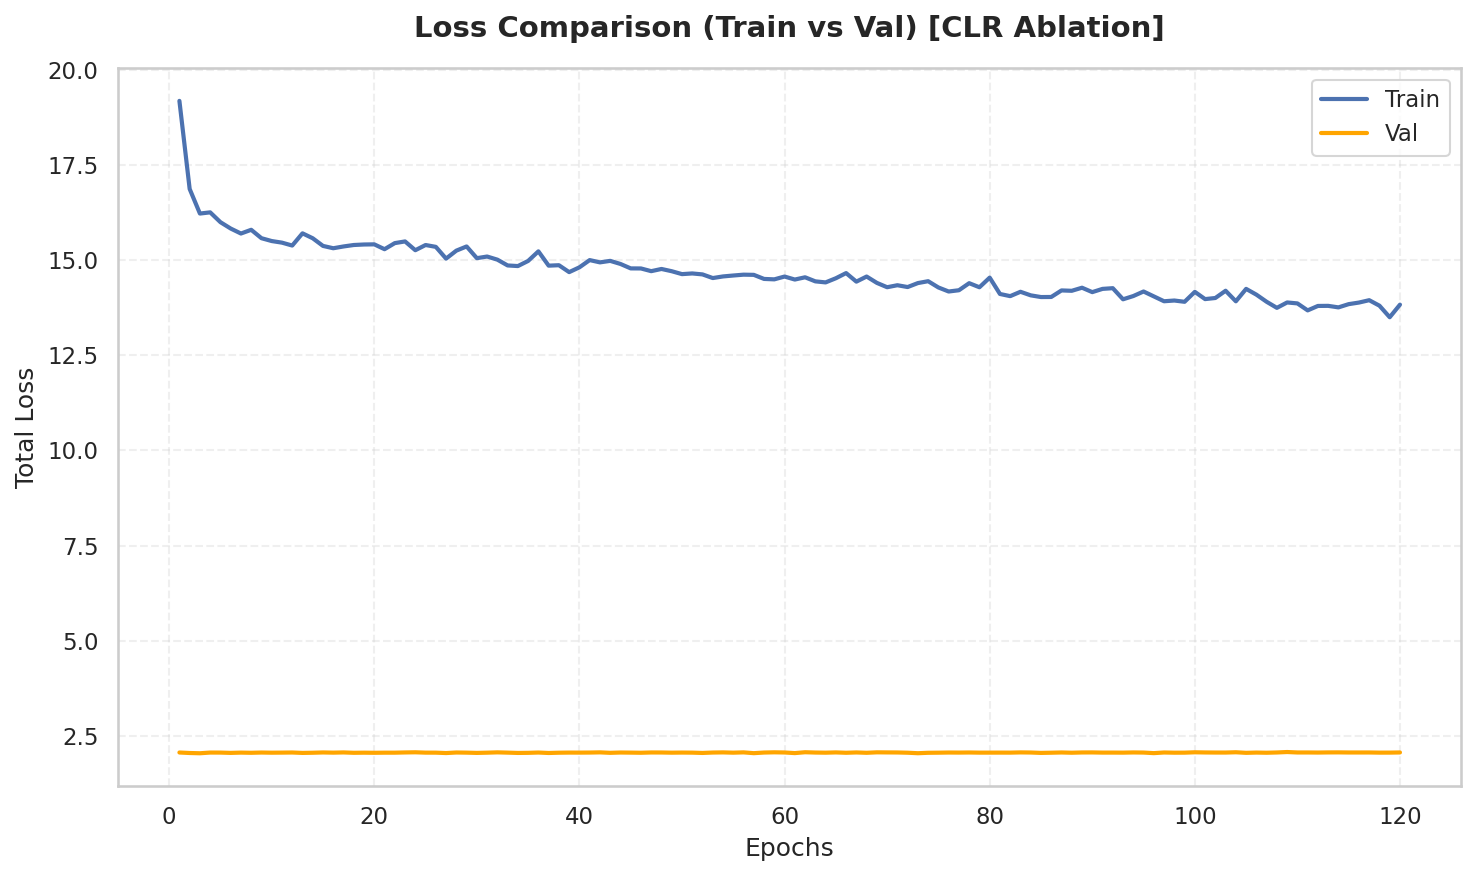

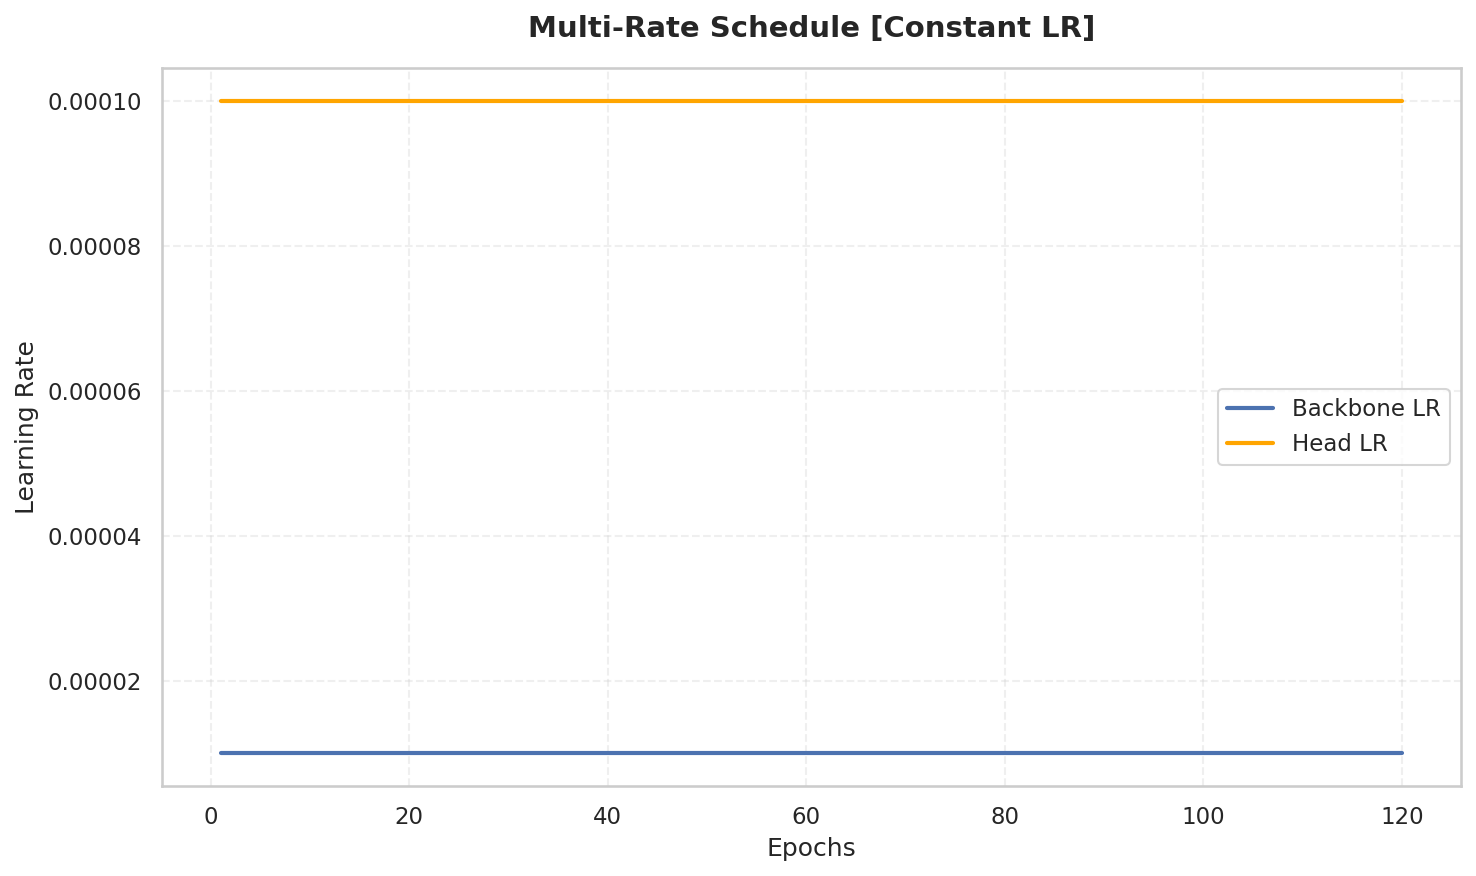

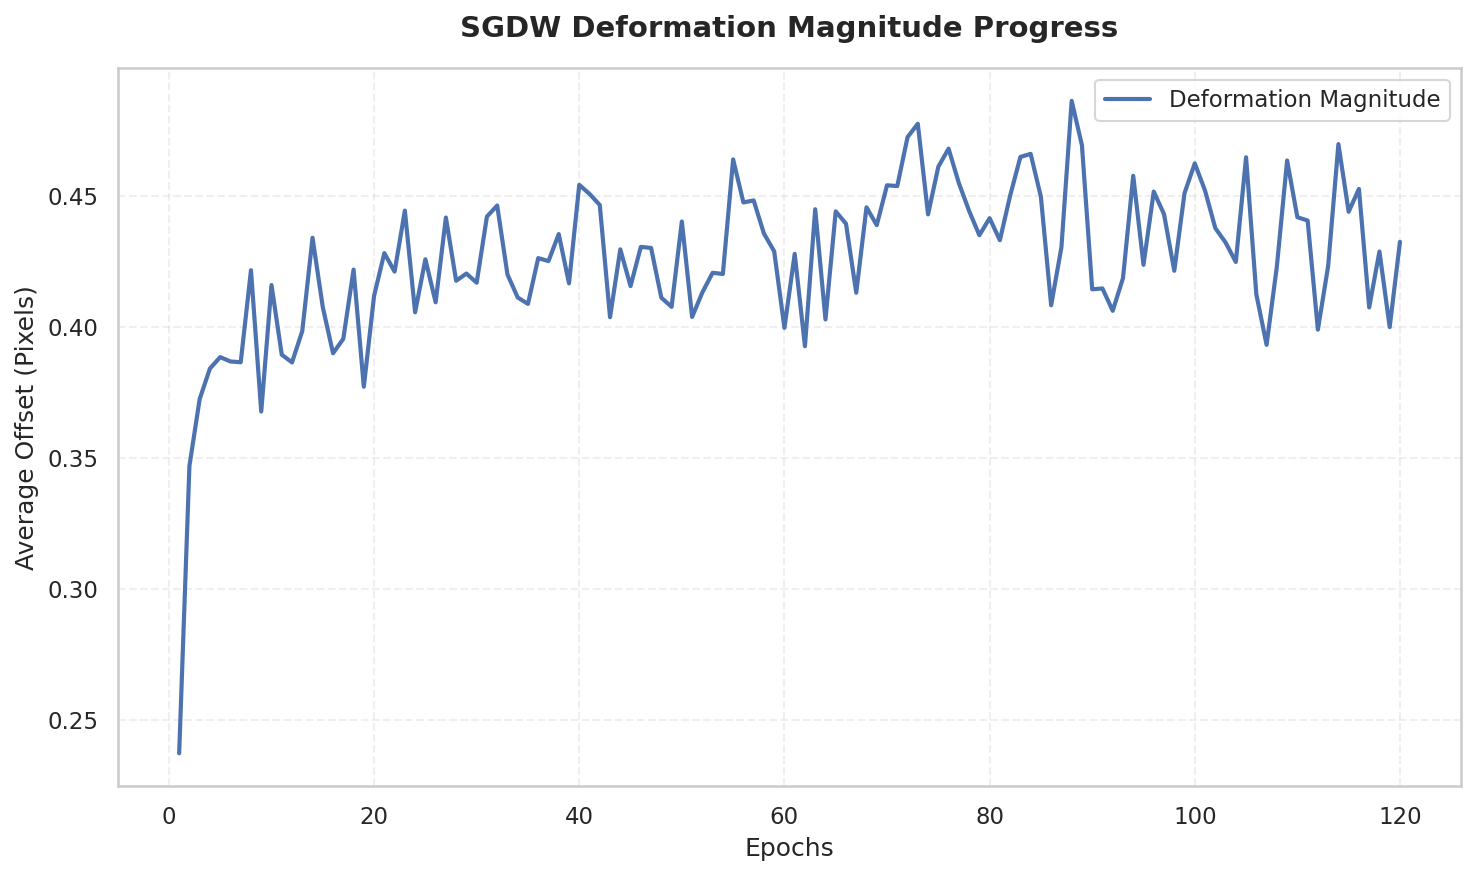

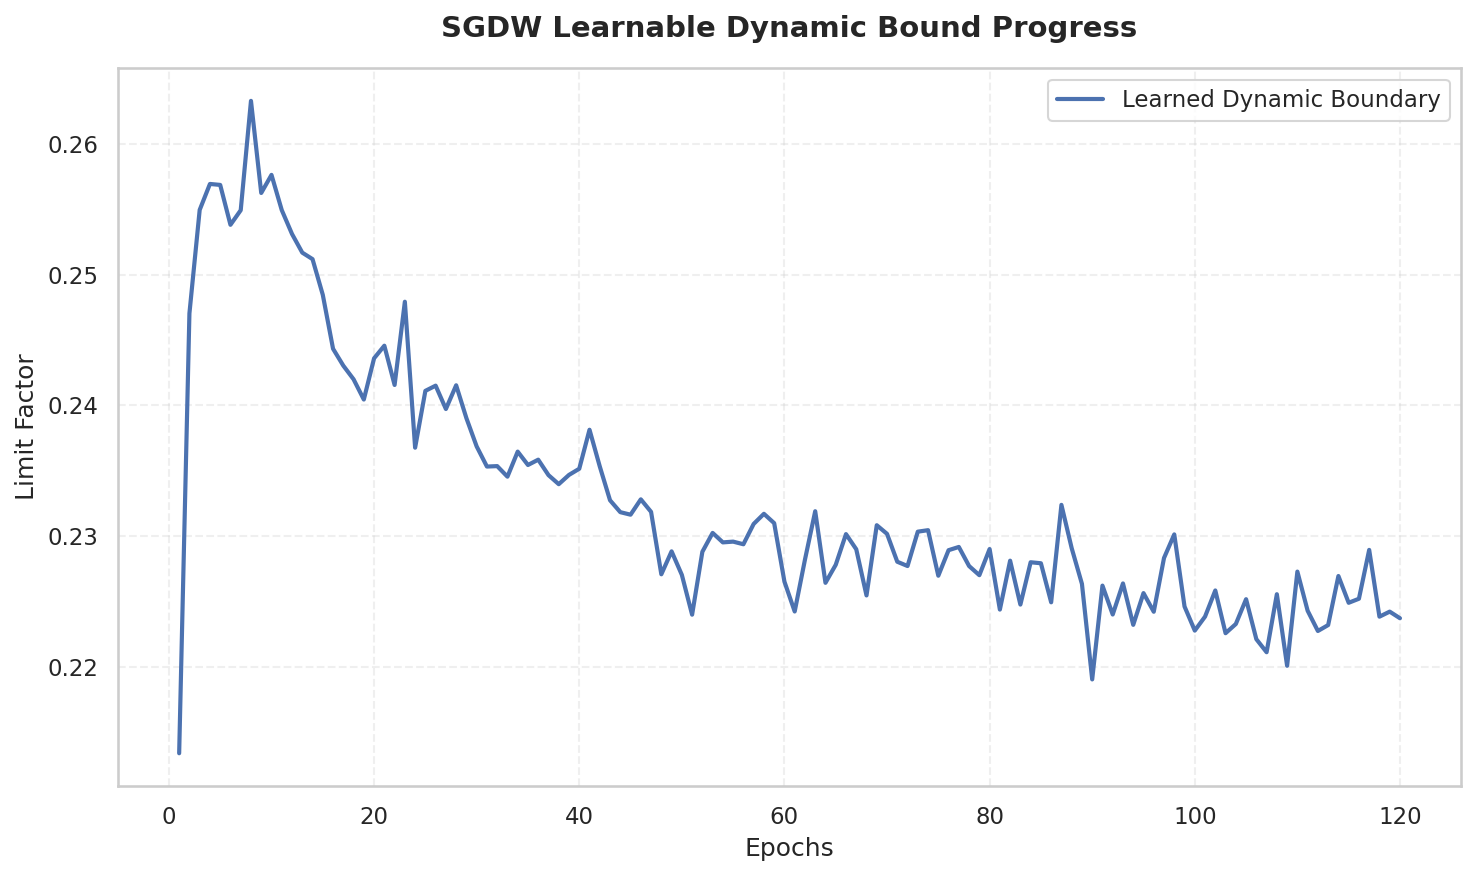

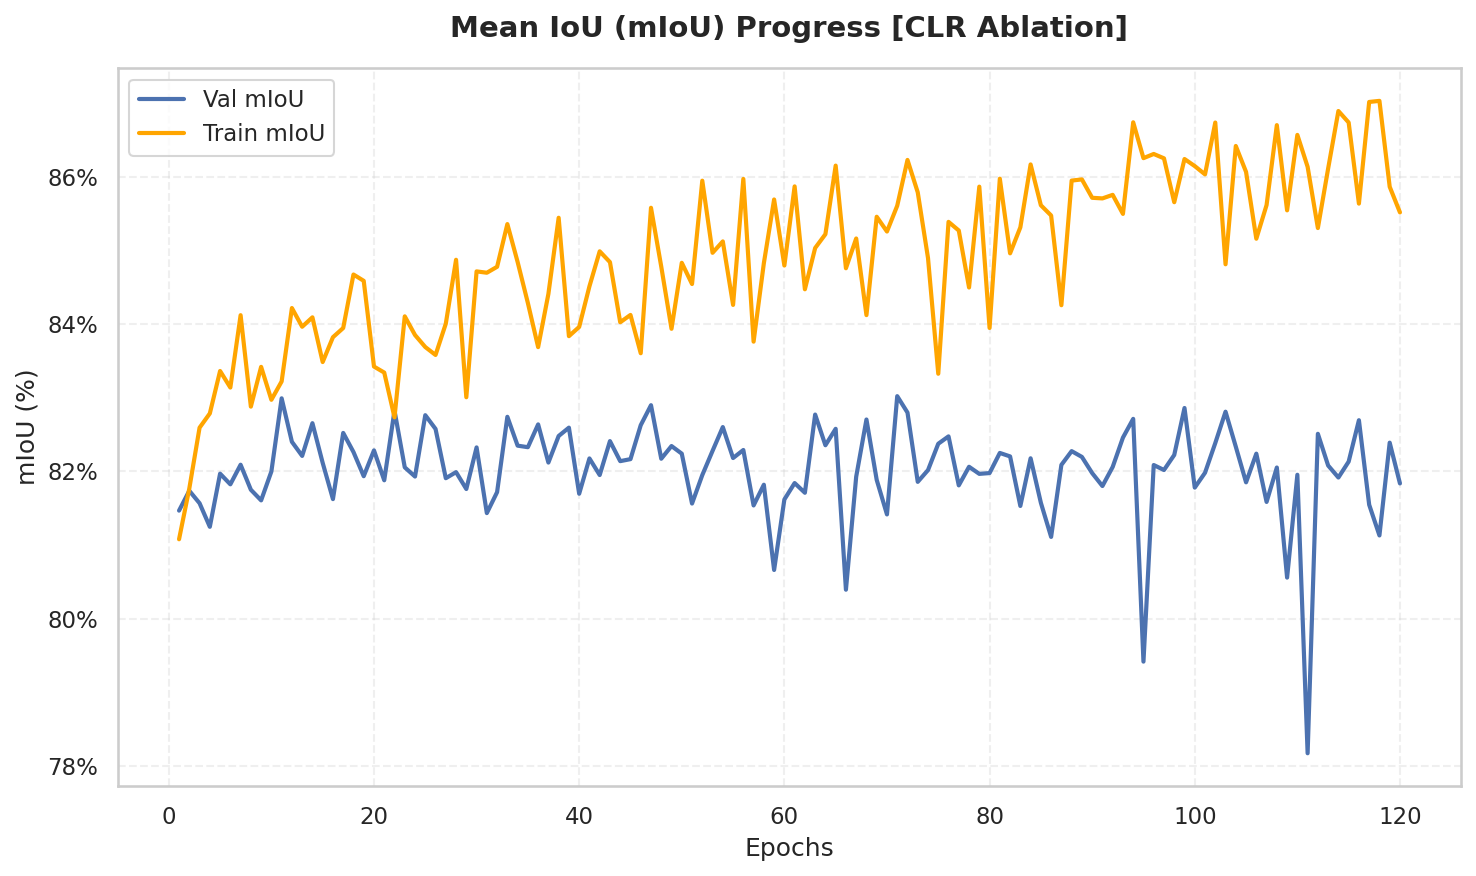

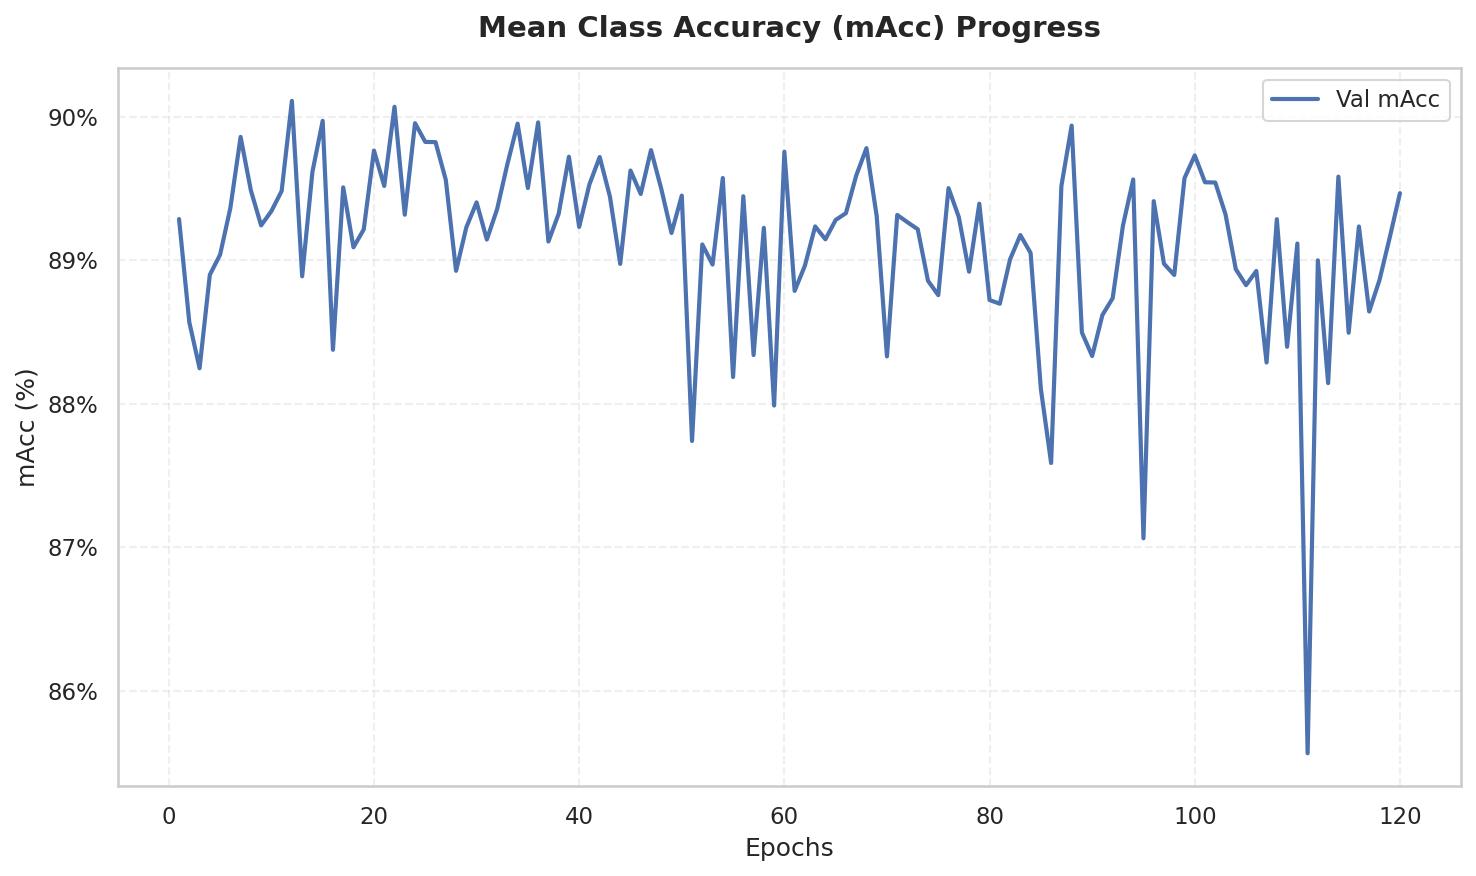

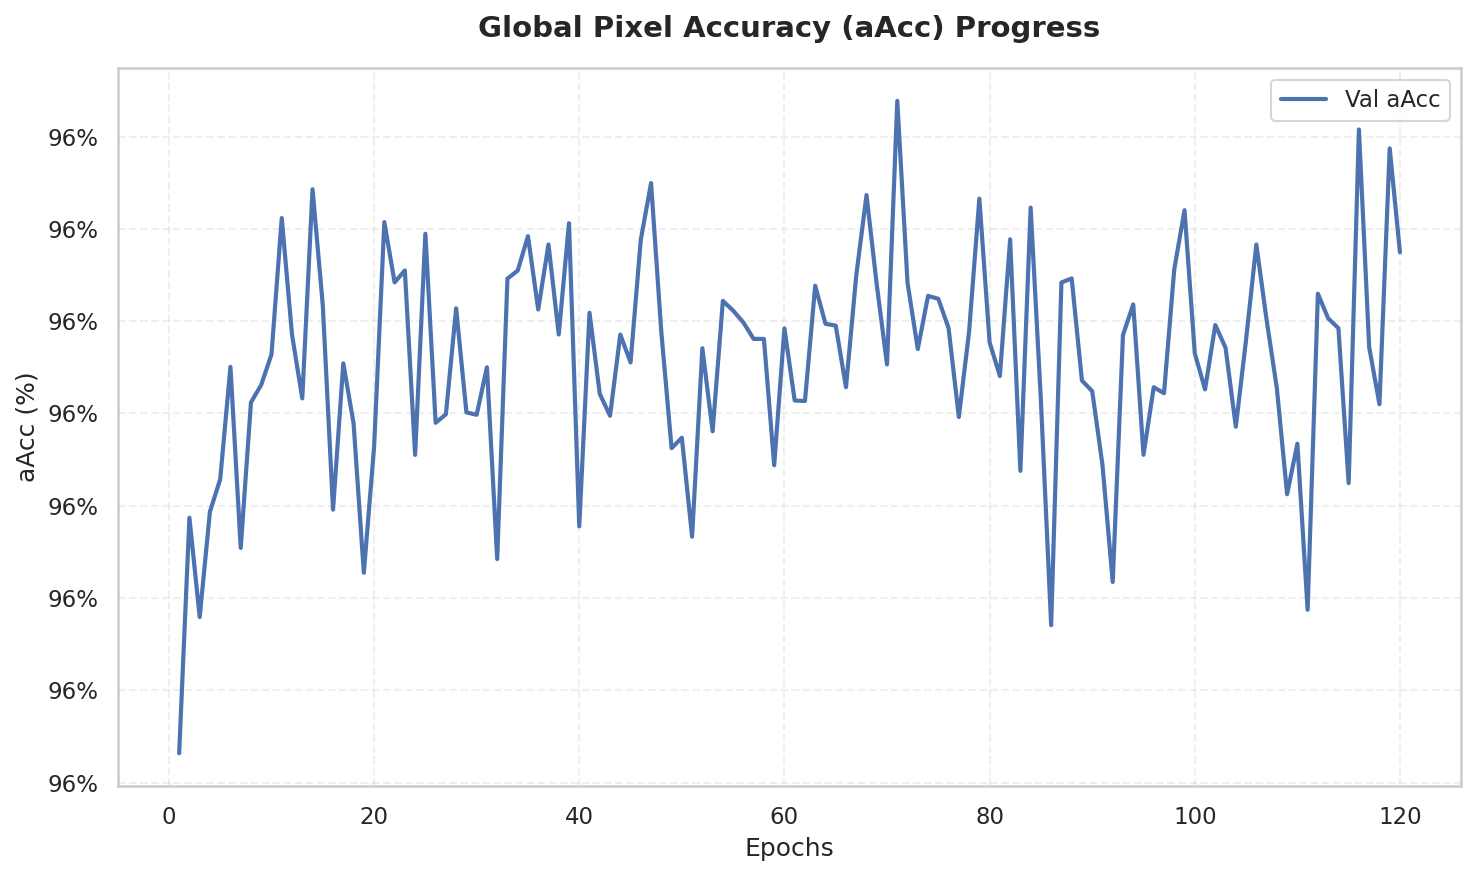

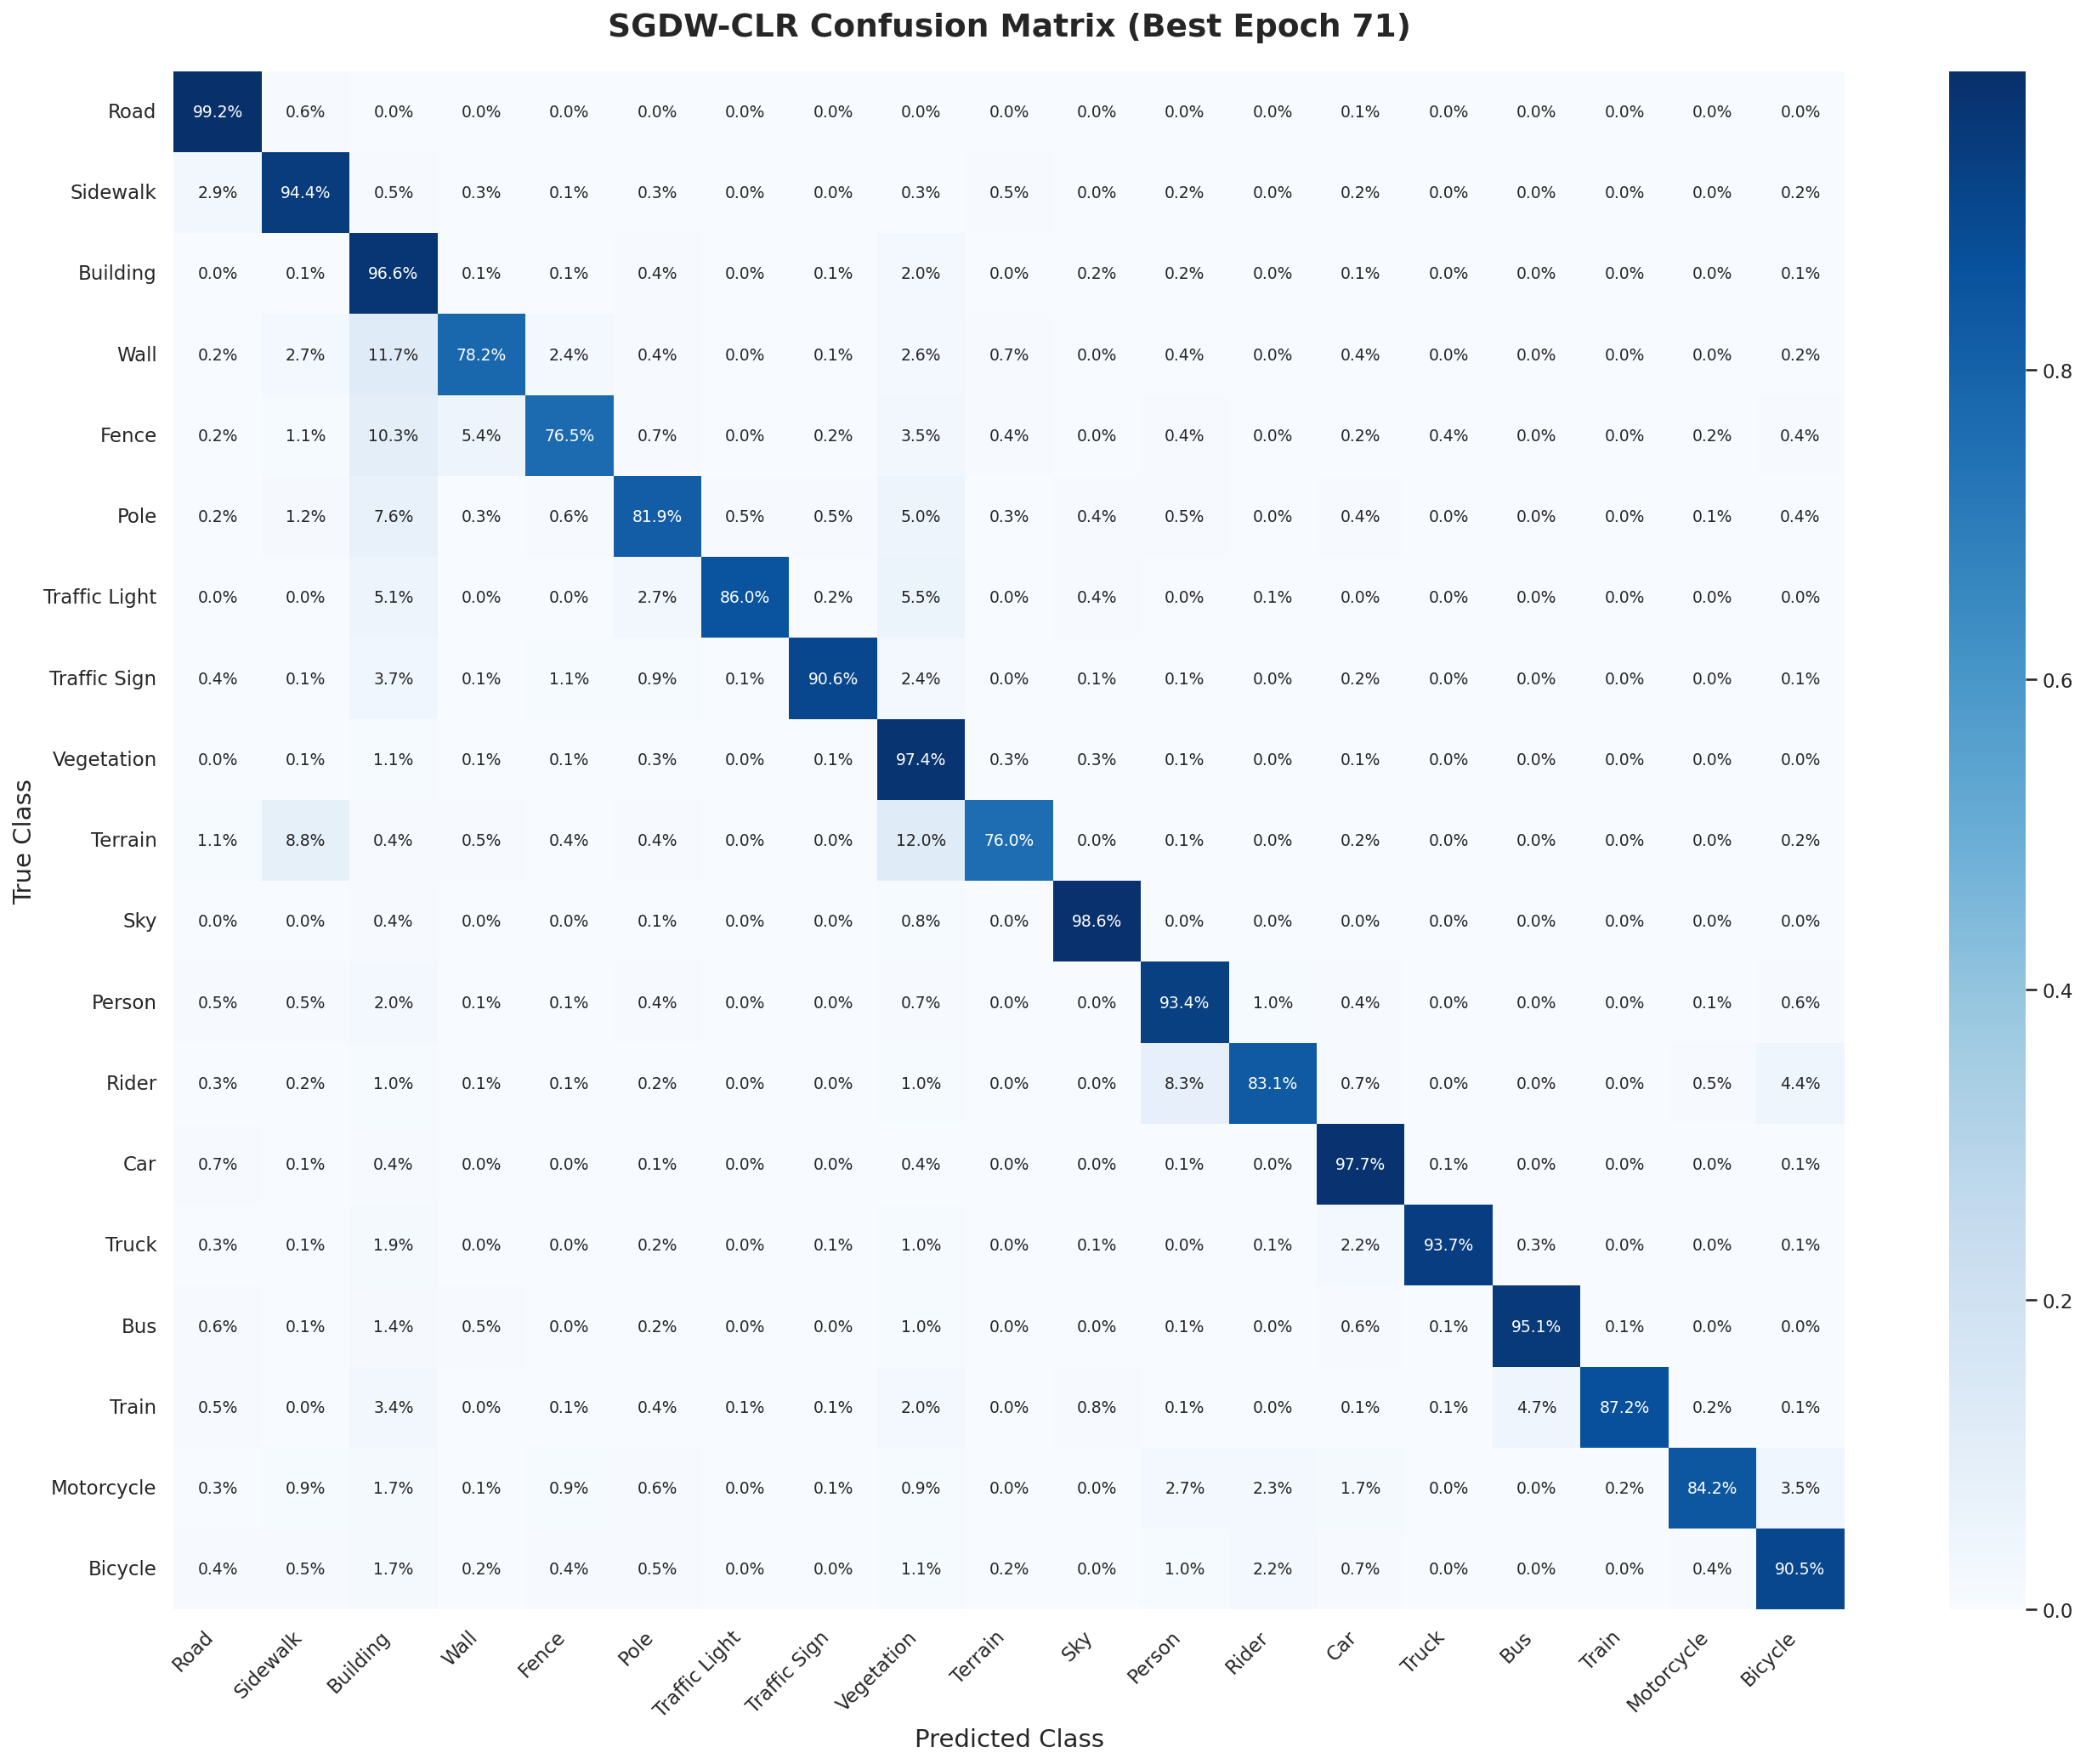


------------------------------------------------------------
Architecture: Multi-Scale SGDW with Dynamic Bounding [CLR Ablation]
Decoder: Mask2Former (Bipartite Native)
Backbone: Swin-Small
Total Parameters:      70,377,100  (70.38 M)
Trainable Parameters:  70,376,524  (70.38 M)
------------------------------------------------------------
SUCCESS: All artifacts and graphs routed to:
/home/hrusikesh-nishank/Pictures/SwinSmall_Mask2Former_SGDW_PixelDecoder_CS_CLR/Results_Export

FINAL RESULTS (Multi-Scale SGDW - Constant LR Ablation)
Best Validation mIoU:           83.02% (Epoch 71)
Final Epoch Pixel Acc (aAcc):   96.84%
Final Epoch Mean IoU (mIoU):    81.84%
Final Epoch Mean Class Acc:     89.47%
Total Training Time:            2 days, 17:43:24
------------------------------------------------------------
CLASS NAME           | IoU (%)    | Accuracy (%)
------------------------------------------------------------
Road                 | 98.61      | 99.24     
Sidewalk             | 87.9

In [7]:
# ============================================================
# STEP 6: EXPORT RESULTS, PLOTS, CONFUSION MATRIX, FINAL SUMMARY
# Target Architecture: Multi-Scale SGDW Mask2Former (Swin-Small)
# Target Dataset: Cityscapes
# Optimization Mode: Constant Learning Rate (CLR) Ablation
# ============================================================

# ------------------------------------------------------------
# SAFETY CHECKS & PATH INHERITANCE (No duplicate imports)
# ------------------------------------------------------------
required_globals = [
    "history", "model", "CLASS_NAMES", "CLASSES",
    "CHECKPOINT_DIR", "best_record", "DEVICE"
]
missing = [k for k in required_globals if k not in globals()]
if missing:
    raise NameError(f"Missing required variables from previous steps: {missing}")

IGNORE_INDEX = globals().get("IGNORE_INDEX", 255)
# Ensure fallback points to the CLR ablation directory
FINAL_SAVE_DIR = globals().get("FINAL_SAVE_DIR", Path("/home/hrusikesh-nishank/Pictures/SwinSmall_Mask2Former_SGDW_PixelDecoder_CS_CLR/Results_Export"))
FINAL_SAVE_DIR.mkdir(parents=True, exist_ok=True)
print(f"Final export directory validated: {FINAL_SAVE_DIR.resolve()}\n")

# ------------------------------------------------------------
# AUTOMATED MATRIX RECOVERY PROTOCOL (CRASH PROOF)
# ------------------------------------------------------------
BEST_CONF_MATRIX = globals().get("best_conf_matrix", globals().get("val_conf_matrix", None))

if BEST_CONF_MATRIX is None and "val_loader" in globals() and "model" in globals():
    print("[!] Confusion matrix missing from RAM. Reconstructing from Best Checkpoint...")
    # Updated to load the CLR specific checkpoint
    best_ckpt_path = CHECKPOINT_DIR / "best_model_sgdw_cs_clr.pt"
    
    if best_ckpt_path.exists():
        ckpt = torch.load(best_ckpt_path.as_posix(), map_location=DEVICE, weights_only=False)
        model.load_state_dict(ckpt["model_state_dict"])
        model.eval()
        
        reconstructed_cm = np.zeros((CLASSES, CLASSES), dtype=np.int64)
        
        def _fast_confusion_matrix(y_true, y_pred, num_classes):
            idx = num_classes * y_true + y_pred
            return np.bincount(idx, minlength=num_classes**2).reshape(num_classes, num_classes)

        def _build_semantic_targets(mask_labels, class_labels, image_size):
            H, W = image_size
            targets = torch.full((len(mask_labels), H, W), fill_value=IGNORE_INDEX, dtype=torch.long, device=mask_labels[0].device)
            for b in range(len(mask_labels)):
                if class_labels[b].numel() == 0: continue
                for inst_idx, cls_id in enumerate(class_labels[b]):
                    if int(cls_id.item()) == IGNORE_INDEX: continue
                    targets[b][mask_labels[b][inst_idx] > 0.5] = int(cls_id.item())
            return targets
        
        USE_AMP = torch.cuda.is_available()
        pbar = tqdm(val_loader, total=len(val_loader), desc="Reconstructing Metrics (TTA)", leave=False)
        
        with torch.no_grad():
            for images, mask_labels, class_labels in pbar:
                images = images.to(DEVICE, non_blocking=True)
                _, _, val_h, val_w = images.shape
                
                mask_labels = [m.to(DEVICE, non_blocking=True) for m in mask_labels]
                class_labels = [c.to(DEVICE, non_blocking=True) for c in class_labels]
                dense_targets = _build_semantic_targets(mask_labels, class_labels, (val_h, val_w))

                scales = [0.75, 1.0, 1.25]
                final_logits = torch.zeros((images.shape[0], CLASSES, val_h, val_w), device=DEVICE, dtype=torch.float32)
                
                for scale in scales:
                    sH, sW = (int(val_h * scale) // 32) * 32, (int(val_w * scale) // 32) * 32 
                    scaled_img = F.interpolate(images, size=(sH, sW), mode='bilinear', align_corners=False)
                    
                    with torch.autocast(device_type="cuda", enabled=USE_AMP):
                        outputs = model(pixel_values=scaled_img)
                        m_preds = F.interpolate(outputs.masks_queries_logits, size=(val_h, val_w), mode="bilinear", align_corners=False)
                        m_cls = F.softmax(outputs.class_queries_logits, dim=-1)[..., :-1]
                        final_logits += torch.einsum("bqc,bqhw->bchw", m_cls, m_preds.sigmoid()).float()
                        
                        outputs_f = model(pixel_values=torch.flip(scaled_img, dims=[3]))
                        m_preds_f = F.interpolate(outputs_f.masks_queries_logits, size=(val_h, val_w), mode="bilinear", align_corners=False)
                        m_cls_f = F.softmax(outputs_f.class_queries_logits, dim=-1)[..., :-1]
                        flip_logits = torch.einsum("bqc,bqhw->bchw", m_cls_f, m_preds_f.sigmoid())
                        final_logits += torch.flip(flip_logits, dims=[3]).float()
                        
                semantic_logits = final_logits / (len(scales) * 2)
                
                preds = torch.argmax(semantic_logits, dim=1).cpu().numpy().astype(np.int64)
                targets_np = dense_targets.cpu().numpy().astype(np.int64)
                valid = (targets_np != IGNORE_INDEX)
                if valid.any():
                    reconstructed_cm += _fast_confusion_matrix(targets_np[valid], preds[valid], CLASSES)
                    
        BEST_CONF_MATRIX = reconstructed_cm
        print("[*] Reconstruction Complete! Restoring class-wise scores.")
    else:
        print("[!] Could not locate best CLR checkpoint on disk. Class-wise metrics will remain empty.")

# ------------------------------------------------------------
# BUILD MAIN DATAFRAME
# ------------------------------------------------------------
num_epochs = len(history["epoch"])

def get_hist_col(key, fallback_key=None):
    col = history.get(key, [])
    if len(col) == num_epochs: return col
    if fallback_key and len(history.get(fallback_key, [])) == num_epochs: return history[fallback_key]
    if len(col) > 0:
        return col + [np.nan] * (num_epochs - len(col)) if len(col) < num_epochs else col[:num_epochs]
    return [np.nan] * num_epochs

df = pd.DataFrame({
    "Epoch": get_hist_col("epoch"),
    "Phase": get_hist_col("phase"),
    "Train_Total_Loss": get_hist_col("train_total_loss"),
    "Train_mIoU": get_hist_col("train_miou"),
    "Val_Total_Loss": get_hist_col("val_total_loss"),
    "Val_mIoU": get_hist_col("val_miou"),
    "Val_mAcc": get_hist_col("val_macc"),
    "Val_aAcc": get_hist_col("val_aacc"),
    "LR_Backbone": get_hist_col("backbone_lr"),
    "LR_Head": get_hist_col("head_lr"),
    "SGDW_Offset_Magnitude": get_hist_col("sgdw_offset_magnitude"),
    "SGDW_Dynamic_Bound": get_hist_col("sgdw_dynamic_bound"), 
    "Epoch_Time_sec": get_hist_col("epoch_time_sec"),
})

total_training_time_sec = float(df["Epoch_Time_sec"].sum()) if not df["Epoch_Time_sec"].isna().all() else 0.0
total_time_str = str(timedelta(seconds=int(total_training_time_sec)))
df["Total_Training_Session_Time"] = total_time_str

# ------------------------------------------------------------
# PREPARE CLASS-WISE DATA
# ------------------------------------------------------------
class_wise_data = []
if BEST_CONF_MATRIX is not None:
    tp = np.diag(BEST_CONF_MATRIX)
    fp = BEST_CONF_MATRIX.sum(axis=0) - tp
    fn = BEST_CONF_MATRIX.sum(axis=1) - tp
    
    iou_per_class = tp / (tp + fp + fn + 1e-10)
    acc_per_class = tp / (tp + fn + 1e-10)
    
    for i, name in enumerate(CLASS_NAMES):
        class_wise_data.append({
            "Class Name": name,
            "IoU (%)": float(iou_per_class[i] * 100),
            "Accuracy (%)": float(acc_per_class[i] * 100)
        })

# ------------------------------------------------------------
# EXPORT FINAL RESULTS CSV & EXCEL
# ------------------------------------------------------------
def safe_pct(val):
    if pd.isna(val) or np.isnan(val): return 0.0
    return val if val > 1.0 else val * 100.0

final_v_acc = safe_pct(df["Val_aAcc"].iloc[-1])
final_mIoU = safe_pct(df["Val_mIoU"].iloc[-1])
final_mAcc = safe_pct(df["Val_mAcc"].iloc[-1])

if "val_miou" in history and len(history["val_miou"]) > 0:
    best_miou_raw = max(history["val_miou"])
    best_idx = history["val_miou"].index(best_miou_raw)
    best_epoch = history["epoch"][best_idx]
    best_miou = safe_pct(best_miou_raw)
else:
    best_epoch = best_record.get("best_epoch", -1)
    best_miou = safe_pct(best_record.get("best_miou", 0.0))

final_global_data = [
    {"Metric": "Best Validation mIoU", "Value": f"{best_miou:.2f}%"},
    {"Metric": "Global Pixel Accuracy (aAcc)", "Value": f"{final_v_acc:.2f}%"},
    {"Metric": "Final Epoch Mean IoU (mIoU)", "Value": f"{final_mIoU:.2f}%"},
    {"Metric": "Final Epoch Mean Class Accuracy (mAcc)", "Value": f"{final_mAcc:.2f}%"},
    {"Metric": "Total Training Time", "Value": total_time_str}
]

# Update filenames for CLR tracking
pd.DataFrame(final_global_data).to_csv(FINAL_SAVE_DIR / "finalresults_sgdw_clr.csv", index=False)

excel_path = FINAL_SAVE_DIR / "Training_Metrics_Report_SGDW_CLR.xlsx"
with pd.ExcelWriter(excel_path, engine='openpyxl') as writer:
    df.to_excel(writer, sheet_name='Epoch_Metrics', index=False)
    if class_wise_data:
        pd.DataFrame(class_wise_data).to_excel(writer, sheet_name='Class_Wise_Results', index=False)

# ------------------------------------------------------------
# STANDARD SEPARATE PLOTS (INDIVIDUAL METRICS)
# ------------------------------------------------------------
sns.set_style("whitegrid")

def save_separate_plot(filename, title, ylabel, train_data, val_data=None, label1="Train", label2="Val"):
    plt.figure(figsize=(10, 6))
    
    epochs_range = range(1, len(train_data) + 1)
    train_clean = np.array(train_data, dtype=float)
    
    if not np.isnan(train_clean).all():
        plt.plot(epochs_range, train_clean, label=label1, lw=2)
    
    if val_data is not None:
        val_clean = np.array(val_data, dtype=float)
        if not np.isnan(val_clean).all():
            plt.plot(epochs_range, val_clean, label=label2, lw=2, color='orange')
            
    if "(%)" in ylabel:
        plt.gca().yaxis.set_major_formatter(plt.FuncFormatter(lambda x, loc: "{:,}%".format(int(x))))

    plt.title(title, fontsize=14, fontweight='bold', pad=15)
    plt.xlabel("Epochs", fontsize=12)
    plt.ylabel(ylabel, fontsize=12)
    plt.legend()
    plt.grid(True, alpha=0.3, linestyle='--')
    plt.tight_layout()
    plt.savefig(FINAL_SAVE_DIR / f"{filename}.png", dpi=600, bbox_inches='tight')
    plt.show() 
    plt.close()

# Extract Data
train_loss = df["Train_Total_Loss"].tolist()
val_loss = df["Val_Total_Loss"].tolist()
offset_magnitude = df["SGDW_Offset_Magnitude"].tolist()
dynamic_bound = df["SGDW_Dynamic_Bound"].tolist()

def ensure_percentage(series):
    if series.isna().all(): return None
    data = series.tolist()
    return [x * 100 if (x is not None and x <= 1.0) else x for x in data]

train_miou = ensure_percentage(df["Train_mIoU"])
val_miou = ensure_percentage(df["Val_mIoU"])
val_aacc = ensure_percentage(df["Val_aAcc"])
val_macc = ensure_percentage(df["Val_mAcc"])

lr_backbone = df["LR_Backbone"].tolist()
lr_head = df["LR_Head"].tolist()

# 1. Loss & Mechanics Plots (Appended _clr to filenames)
save_separate_plot("loss_comparison_clr", "Loss Comparison (Train vs Val) [CLR Ablation]", "Total Loss", train_loss, val_loss)
save_separate_plot("learning_rate_progress_clr", "Multi-Rate Schedule [Constant LR]", "Learning Rate", lr_backbone, lr_head, label1="Backbone LR", label2="Head LR")
if not df["SGDW_Offset_Magnitude"].isna().all():
    save_separate_plot("sgdw_offset_magnitude_clr", "SGDW Deformation Magnitude Progress", "Average Offset (Pixels)", offset_magnitude, label1="Deformation Magnitude")
if not df["SGDW_Dynamic_Bound"].isna().all():
    save_separate_plot("sgdw_dynamic_bound_clr", "SGDW Learnable Dynamic Bound Progress", "Limit Factor", dynamic_bound, label1="Learned Dynamic Boundary")

# 2. Individual Evaluation Metric Plots (Appended _clr to filenames)
save_separate_plot("miou_progress_clr", "Mean IoU (mIoU) Progress [CLR Ablation]", "mIoU (%)", val_miou, train_miou, label1="Val mIoU", label2="Train mIoU")
save_separate_plot("macc_progress_clr", "Mean Class Accuracy (mAcc) Progress", "mAcc (%)", val_macc, label1="Val mAcc")
save_separate_plot("aacc_progress_clr", "Global Pixel Accuracy (aAcc) Progress", "aAcc (%)", val_aacc, label1="Val aAcc")

# ------------------------------------------------------------
# PERCENTAGE-BASED CONFUSION MATRIX
# ------------------------------------------------------------
if BEST_CONF_MATRIX is not None:
    plt.figure(figsize=(18, 14)) 
    
    cm_normalized = BEST_CONF_MATRIX.astype('float') / (BEST_CONF_MATRIX.sum(axis=1)[:, np.newaxis] + 1e-10)
    
    sns.heatmap(
        cm_normalized, annot=True, fmt='.1%', cmap='Blues', 
        xticklabels=CLASS_NAMES, yticklabels=CLASS_NAMES, 
        annot_kws={"size": 9}
    ) 
    
    plt.title(f"SGDW-CLR Confusion Matrix (Best Epoch {best_epoch})", fontsize=18, fontweight='bold', pad=20)
    plt.ylabel('True Class', fontsize=14)
    plt.xlabel('Predicted Class', fontsize=14)
    plt.xticks(rotation=45, ha='right')
    plt.tight_layout()
    plt.savefig(FINAL_SAVE_DIR / "confusion_matrix_percentages_clr.png", dpi=600, bbox_inches='tight')
    plt.show() 
    plt.close()

# ------------------------------------------------------------
# FINAL PRINT SUMMARY
# ------------------------------------------------------------
total_params = sum(p.numel() for p in model.parameters())
trainable_params = sum(p.numel() for p in model.parameters() if p.requires_grad)

print(f"\n" + "-"*60)
print(f"Architecture: Multi-Scale SGDW with Dynamic Bounding [CLR Ablation]")
print(f"Decoder: Mask2Former (Bipartite Native)")
print(f"Backbone: Swin-Small")
print(f"Total Parameters:      {total_params:,}  ({total_params/1e6:.2f} M)")
print(f"Trainable Parameters:  {trainable_params:,}  ({trainable_params/1e6:.2f} M)")
print(f"-"*60)
print(f"SUCCESS: All artifacts and graphs routed to:\n{FINAL_SAVE_DIR.resolve()}")
print("\n" + "="*60)
print(f"FINAL RESULTS (Multi-Scale SGDW - Constant LR Ablation)")
print("="*60)
print(f"Best Validation mIoU:           {best_miou:.2f}% (Epoch {best_epoch})")
print(f"Final Epoch Pixel Acc (aAcc):   {final_v_acc:.2f}%")
print(f"Final Epoch Mean IoU (mIoU):    {final_mIoU:.2f}%")
print(f"Final Epoch Mean Class Acc:     {final_mAcc:.2f}%")
print(f"Total Training Time:            {total_time_str}")
print("-" * 60)
print(f"{'CLASS NAME':<20} | {'IoU (%)':<10} | {'Accuracy (%)':<10}")
print("-" * 60)

if class_wise_data:
    for item in class_wise_data:
        print(f"{item['Class Name']:<20} | {item['IoU (%)']:<10.2f} | {item['Accuracy (%)']:<10.2f}")

Presentation graph will be exported to: /home/hrusikesh-nishank/Pictures/SwinSmall_Mask2Former_SGDW_PixelDecoder_CS_CLR/Results_Export
[*] Filtered presentation graph saved successfully to:
/home/hrusikesh-nishank/Pictures/SwinSmall_Mask2Former_SGDW_PixelDecoder_CS_CLR/Results_Export/presentation_metrics_progress_sgdw_clr.png


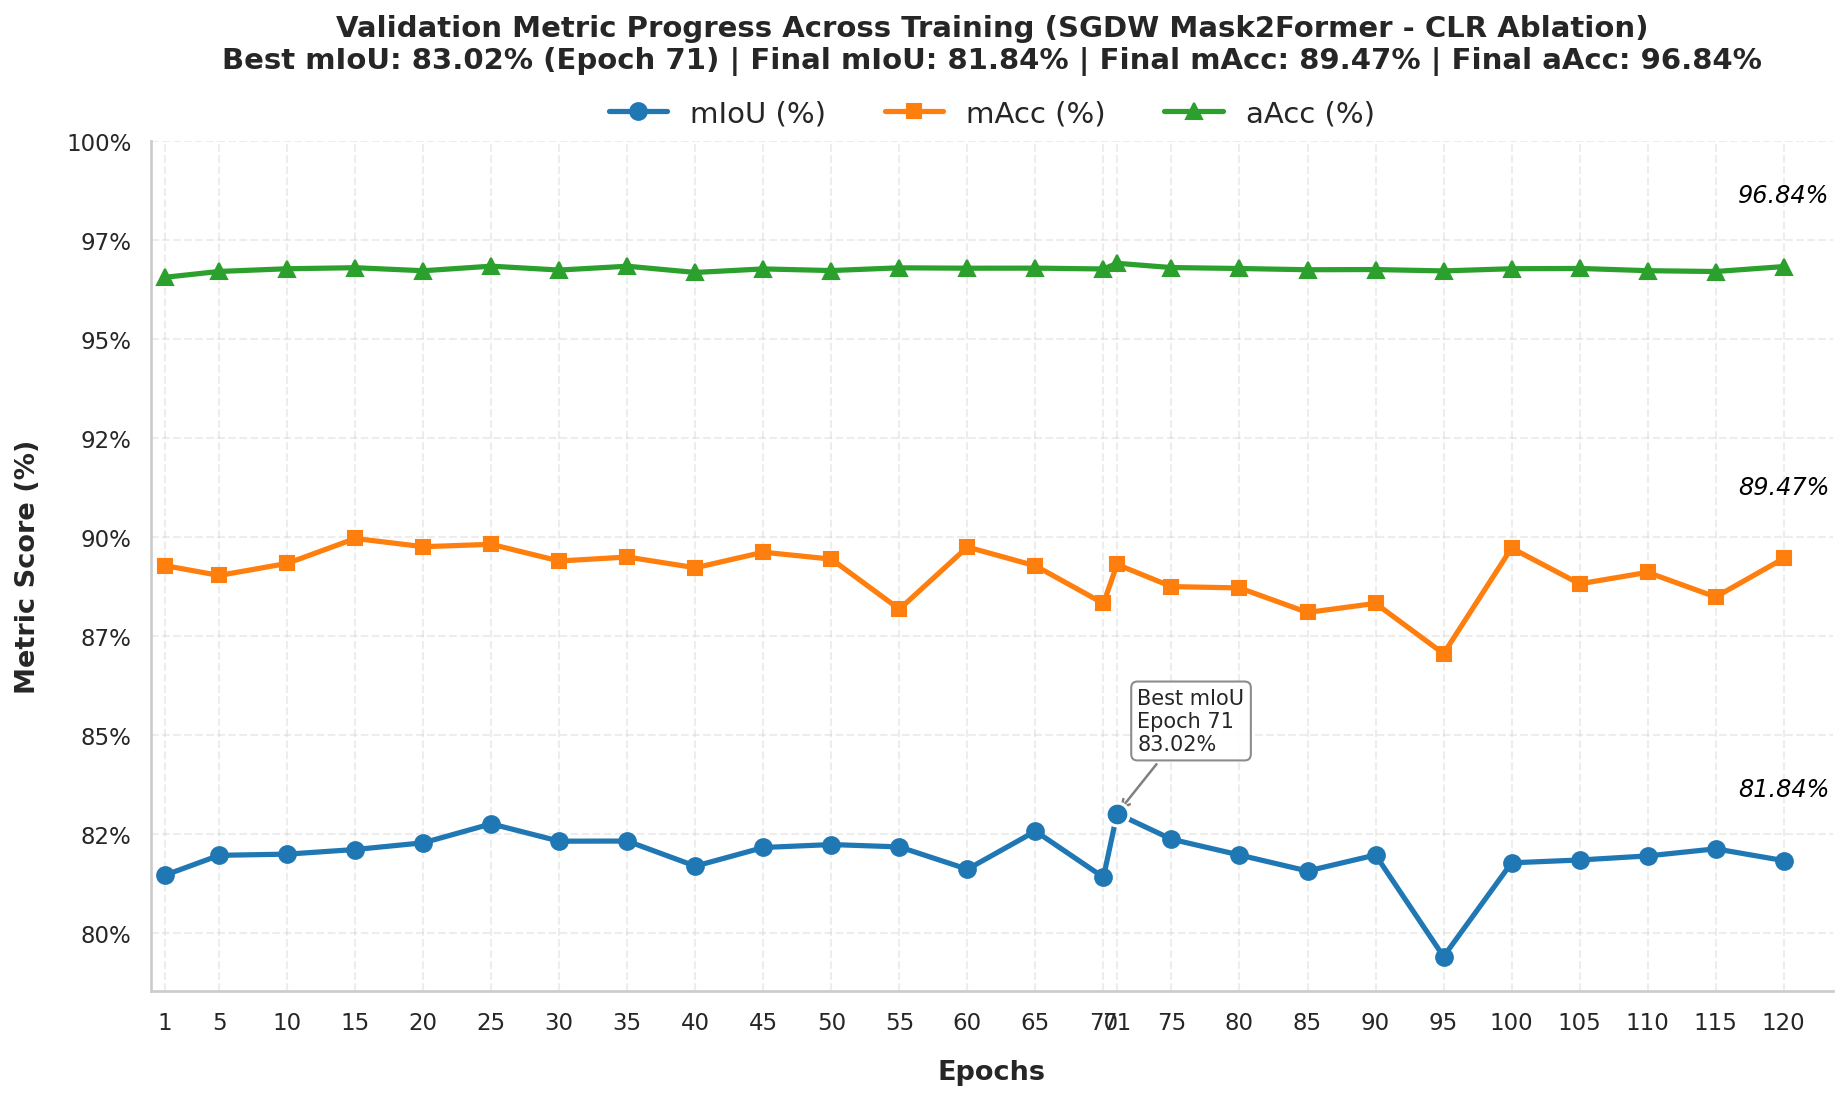

In [8]:
# ============================================================
# STEP 7: PRESENTATION-READY MULTI-METRIC PROGRESS GRAPH
# Target Architecture: Semantically-Guided Deformable Windows (SGDW) Swin-Small [CLR Ablation]
# Target Dataset: Cityscapes
# ============================================================

# ------------------------------------------------------------
# SAFETY CHECKS & PATH INHERITANCE
# ------------------------------------------------------------
required_globals = ["history"]
missing = [k for k in required_globals if k not in globals()]
if missing:
    raise NameError(f"Missing required variables from previous steps: {missing}")

if "val_miou" not in history or len(history["val_miou"]) == 0:
    raise ValueError("history['val_miou'] is empty. Run training (Step 5) before Step 7.")

FINAL_SAVE_DIR = globals().get("FINAL_SAVE_DIR", Path("/home/hrusikesh-nishank/Pictures/SwinSmall_Mask2Former_SGDW_PixelDecoder_CS_CLR/Results_Export"))
FINAL_SAVE_DIR.mkdir(parents=True, exist_ok=True)
print(f"Presentation graph will be exported to: {FINAL_SAVE_DIR.resolve()}")

# ------------------------------------------------------------
# PREPARE EPOCHS & DATA
# ------------------------------------------------------------
all_epochs = history["epoch"]
PLOT_INTERVAL = 5

def safe_pct(val):
    if pd.isna(val) or np.isnan(val): return 0.0
    return val * 100.0 if val <= 1.0 else float(val)

best_miou_raw = max(history["val_miou"])
best_idx = history["val_miou"].index(best_miou_raw)
best_miou = safe_pct(best_miou_raw)
best_miou_epoch = all_epochs[best_idx]

filtered_epochs_set = set([e for e in all_epochs if e == 1 or e % PLOT_INTERVAL == 0] + [all_epochs[-1], best_miou_epoch])
filtered_epochs = sorted(list(filtered_epochs_set))

indices = [all_epochs.index(e) for e in filtered_epochs]

miou_scores = [safe_pct(history["val_miou"][i]) for i in indices]
macc_scores = [safe_pct(history["val_macc"][i]) for i in indices]
aacc_scores = [safe_pct(history["val_aacc"][i]) for i in indices]

final_miou = safe_pct(history["val_miou"][-1])
final_macc = safe_pct(history["val_macc"][-1])
final_aacc = safe_pct(history["val_aacc"][-1])
final_x = all_epochs[-1]

# ------------------------------------------------------------
# PLOT SETUP 
# ------------------------------------------------------------
fig, ax = plt.subplots(figsize=(12.5, 7.5)) 

color_miou = '#1f77b4'  
color_macc = '#ff7f0e'  
color_aacc = '#2ca02c'  

ax.plot(filtered_epochs, miou_scores, marker='o', linewidth=2.5, markersize=8, label='mIoU (%)', color=color_miou)
ax.plot(filtered_epochs, macc_scores, marker='s', linewidth=2.5, markersize=7, label='mAcc (%)', color=color_macc)
ax.plot(filtered_epochs, aacc_scores, marker='^', linewidth=2.5, markersize=8, label='aAcc (%)', color=color_aacc)

# ------------------------------------------------------------
# AXIS LABELS
# ------------------------------------------------------------
ax.set_xlabel('Epochs', fontsize=13, fontweight='bold', labelpad=12)
ax.set_ylabel('Metric Score (%)', fontsize=13, fontweight='bold', labelpad=12)
ax.set_xticks(filtered_epochs)

ax.yaxis.set_major_formatter(plt.FuncFormatter(lambda x, loc: f"{int(x)}%"))

# ------------------------------------------------------------
# BEST mIoU ANNOTATION 
# ------------------------------------------------------------
ax.scatter(best_miou_epoch, best_miou, s=120, zorder=5, color=color_miou, edgecolors='white', linewidth=1.5)

if best_miou_epoch <= (max(filtered_epochs) * 0.6):
    best_text_x = best_miou_epoch + 1.5
    best_ha = "left"
else:
    best_text_x = best_miou_epoch - 1.5
    best_ha = "right"

ax.annotate(
    f'Best mIoU\nEpoch {best_miou_epoch}\n{best_miou:.2f}%',
    xy=(best_miou_epoch, best_miou),
    xytext=(best_text_x, best_miou + 1.5),
    fontsize=10, ha=best_ha, va='bottom',
    bbox=dict(boxstyle="round,pad=0.3", fc="white", ec="gray", alpha=0.9),
    arrowprops=dict(arrowstyle='->', color='gray', lw=1.2)
)

# ------------------------------------------------------------
# END-OF-LINE FINAL VALUE ANNOTATIONS
# ------------------------------------------------------------
offset_y = 1.5

ax.text(final_x, final_miou + offset_y, f'{final_miou:.2f}%', va='bottom', ha='center', fontsize=11.5, fontstyle='italic', color='black')
ax.text(final_x, final_macc + offset_y, f'{final_macc:.2f}%', va='bottom', ha='center', fontsize=11.5, fontstyle='italic', color='black')
ax.text(final_x, final_aacc + offset_y, f'{final_aacc:.2f}%', va='bottom', ha='center', fontsize=11.5, fontstyle='italic', color='black')

ax.set_xlim(left=0, right=max(all_epochs) + (max(all_epochs) * 0.03))
ax.set_ylim(top=100) 

# ------------------------------------------------------------
# STYLING & LEGEND
# ------------------------------------------------------------
ax.legend(loc='upper center', bbox_to_anchor=(0.5, 1.08), ncol=3, frameon=False, fontsize=14)

ax.spines['top'].set_visible(False)
ax.spines['right'].set_visible(False)
ax.spines['bottom'].set_linewidth(1.3)
ax.spines['left'].set_linewidth(1.3)

ax.grid(True, linestyle='--', alpha=0.35)

title_main = "Validation Metric Progress Across Training (SGDW Mask2Former - CLR Ablation)"
title_sub = f"Best mIoU: {best_miou:.2f}% (Epoch {best_miou_epoch}) | Final mIoU: {final_miou:.2f}% | Final mAcc: {final_macc:.2f}% | Final aAcc: {final_aacc:.2f}%"

ax.set_title(
    title_main + "\n" + title_sub,
    fontsize=14, fontweight='bold', pad=35
)

plt.tight_layout()

# ------------------------------------------------------------
# SAVE
# ------------------------------------------------------------
combined_graph_path = FINAL_SAVE_DIR / "presentation_metrics_progress_sgdw_clr.png"
plt.savefig(combined_graph_path, dpi=600, bbox_inches='tight')
print(f"[*] Filtered presentation graph saved successfully to:\n{combined_graph_path.resolve()}")

plt.show()
plt.close()